# Olist Product Recommendation and Customer Retention

This notebook develops CSE303 catalog topic 9.2 using the Olist Brazilian E-Commerce dataset. We will explore customer behavior, recommend relevant products, and estimate repeat-purchase likelihood. The verified pipeline will later support an application with a conversational assistant.

The proposed application user is a marketing employee exploring customer retention opportunities. The prediction horizon and application technology will be decided after assessing the data.

We will develop one section at a time and explain its actual results in [PIPELINE_NOTES.md](PIPELINE_NOTES.md). See [PROJECT_PLAN.md](PROJECT_PLAN.md) for the broader sequence.


## References

- [Olist dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) provides the source tables.
- [Mohab Allam's reference notebook](https://www.kaggle.com/code/mohabovic/eda-satisfaction-prediction-nlp-rfm-deployment/notebook) informs our approach to data preparation, EDA, satisfaction analysis, and segmentation. Specific adaptations will be credited as they are introduced.
- The course kickoff guide and Week 10 recommender starter inform the deliverables and understanding checks.

This first section contains our own loading code.


## How the two reference notebooks are used

| Reference component | Our corresponding section | Current use |
|---|---|---|
| Kaggle loading cleaning and EDA | Sections 1 to 4 | Workflow reference, adapted with validated row grains, explicit missing-data rules, and our own measured plots |
| Kaggle preprocessing Pipeline and ColumnTransformer | Section 6.1 | Adapted to training-only median imputation, scaling, state encoding, and Logistic Regression |
| Kaggle classification workflow | Sections 5 and 6 | Model-development reference with a new future repeat-order target and chronological partitions |
| Kaggle RFM analysis | Section 5.2 | Historical recency, frequency, and monetary concepts adapted to a fixed prediction date and distinct orders |
| Kaggle clustering review NLP and deployment | Later stages | Clustering and application work pending. Review-text NLP remains an optional extension |
| Week 10 baselines and ranking metrics | Sections 5.5 and 6.3 | Popularity and top-K metric formulas adapted to implicit purchase relevance |
| Week 10 content collaborative SVD and hybrid models | Comparative modeling topic | Planned, beyond the current popularity baseline |
| Week 10 cold-start and understanding pack | Baseline checks and later comparison | New-user and single-history checks introduced. Collaborative by-hand calculation and the full deliberate-leak experiment remain pending |

This project is an independent adaptation of the references. Their problem definitions and evaluation assumptions differ from the current tasks. Specific differences and attributions are recorded where introduced. Course materials are kept locally in SOURCE FILES.

[Kaggle reference notebook](https://www.kaggle.com/code/mohabovic/eda-satisfaction-prediction-nlp-rfm-deployment/notebook)


## 1 Load the source tables

Read all nine CSV files and record their dimensions. Keep the tables separate so that their row meanings and relationships can be inspected before joining them.

Open this notebook in VS Code and select a Python kernel with pandas installed. Run the cells from top to bottom with the repository root as the working directory. Source CSVs should be directly inside `data/raw/`.

`Path` constructs filesystem paths. pandas loads CSV files into DataFrames, which are tables with named columns.


In [1]:
from pathlib import Path

import pandas as pd

print(f"pandas version: {pd.__version__}")


pandas version: 3.1.1


### Locate and check the files

`data_files` maps meaningful table names to the original CSV filenames. Check that the source folder and every required file exist before loading. Relative paths let collaborators run the same code from their own repository root.


In [2]:
project_root = Path.cwd()
data_dir = project_root / "data" / "raw"

if not data_dir.is_dir():
    raise FileNotFoundError(
        "Expected data/raw/ under the working directory. "
        "Run the notebook from the repository root and check the README download instructions."
    )

data_files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

missing_files = [
    filename
    for filename in data_files.values()
    if not (data_dir / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(f"Missing source files: {', '.join(missing_files)}")

print(f"Found all {len(data_files)} required CSV files in data/raw/.")


Found all 9 required CSV files in data/raw/.


### Read the tables and summarize their dimensions

`pd.read_csv()` reads each file into a DataFrame. The `tables` dictionary holds them under meaningful names, such as `tables["customers"]` and `tables["orders"]`.

Postal-code prefixes are identifiers. Loading them with the `string` dtype preserves leading zeros when present in the source. Other types are initially inferred by pandas. Timestamps will be inspected and parsed in a later section.

`.shape[0]` returns row count, and `.shape[1]` returns column count. These counts describe the source tables before cleaning.


In [3]:
postal_code_types = {
    "customer_zip_code_prefix": "string",
    "seller_zip_code_prefix": "string",
    "geolocation_zip_code_prefix": "string",
}

tables = {}

for table_name, filename in data_files.items():
    tables[table_name] = pd.read_csv(
        data_dir / filename,
        dtype=postal_code_types,
    )

summary_rows = []

for table_name, dataframe in tables.items():
    summary_rows.append({
        "table": table_name,
        "rows": dataframe.shape[0],
        "columns": dataframe.shape[1],
    })

data_summary = pd.DataFrame(summary_rows)

print(data_summary.to_string(index=False))
print()
print(f"Loaded {len(tables)} source tables.")


               table    rows  columns
           customers   99441        5
              orders   99441        8
         order_items  112650        7
      order_payments  103886        5
       order_reviews   99224        7
            products   32951        9
             sellers    3095        4
         geolocation 1000163        5
category_translation      71        2

Loaded 9 source tables.


### Observations from this execution

| Table | Rows | Columns |
|---|---:|---:|
| customers | 99,441 | 5 |
| orders | 99,441 | 8 |
| order_items | 112,650 | 7 |
| order_payments | 103,886 | 5 |
| order_reviews | 99,224 | 7 |
| products | 32,951 | 9 |
| sellers | 3,095 | 4 |
| geolocation | 1,000,163 | 5 |
| category_translation | 71 | 2 |

All nine source tables loaded successfully and contain rows. Their row units differ. For example, order items represent products within orders, and payments represent payment records. We will inspect keys and relationships before combining tables.

Missing-value handling, duplicate checks, timestamp parsing, and join validation will be documented in later sections.

**Next checkpoint** — Inspect sample rows, column types, missing values, identifiers, and duplicate keys.

**Suggested commit message** — `feat: start Olist notebook and load source tables`.


## 2 Inspect the source data

Inspect the loaded tables before deciding how to clean or combine them. This section examines sample rows, column types, missing values, repeated records, identifiers, and relationship coverage.

The checks create summaries from the source tables. We will use their results to justify cleaning and join rules in the next checkpoint.


### 2.1 Inspect sample rows

`.head(2)` shows the first two rows of each DataFrame. This helps identify what a row represents and how fields are stored. These examples illustrate structure. They are too small to describe a table's full distribution.

`max_colwidth=40` shortens long values only in the printed display, keeping the saved notebook readable.


In [4]:
for table_name, dataframe in tables.items():
    print(f"Table: {table_name}")
    print(dataframe.head(2).to_string(index=False, max_colwidth=40))
    print()


Table: customers
                     customer_id               customer_unique_id customer_zip_code_prefix         customer_city customer_state
06b8999e2fba1a1fbc88172c00ba8bc7 861eff4711a542e4b93843c6dd7febb0                    14409                franca             SP
18955e83d337fd6b2def6b18a428ac77 290c77bc529b7ac935b93aa66c333dc3                    09790 sao bernardo do campo             SP

Table: orders
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
53cdb2fc8bc7dce0b6741e2150273451 b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27          2018-07-26 14:31:00      

### 2.2 Measure types and missing values

For every column, record its loaded dtype, number of missing values, percentage missing, and number of distinct non-missing values.

`.isna().sum()` counts missing values. Dividing by the row count and multiplying by 100 gives the missing percentage. `.nunique(dropna=True)` counts distinct observed values. This can help identify candidate identifiers, but uniqueness alone does not establish a column's business meaning.

Date fields may still be stored as strings. We will choose and explain their conversion after inspection.


In [5]:
profile_rows = []

for table_name, dataframe in tables.items():
    for column_name in dataframe.columns:
        column = dataframe[column_name]
        missing_count = int(column.isna().sum())
        profile_rows.append({
            "table": table_name,
            "column": column_name,
            "dtype": str(column.dtype),
            "missing_count": missing_count,
            "missing_percent": round(100 * missing_count / len(dataframe), 2),
            "unique_non_missing": int(column.nunique(dropna=True)),
        })

column_profile = pd.DataFrame(profile_rows)

print(column_profile.to_string(index=False))
print()
print("Columns with missing values:")
print(
    column_profile.loc[column_profile["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
    .to_string(index=False)
)


               table                        column   dtype  missing_count  missing_percent  unique_non_missing
           customers                   customer_id     str              0             0.00               99441
           customers            customer_unique_id     str              0             0.00               96096
           customers      customer_zip_code_prefix  string              0             0.00               14994
           customers                 customer_city     str              0             0.00                4119
           customers                customer_state     str              0             0.00                  27
              orders                      order_id     str              0             0.00               99441
              orders                   customer_id     str              0             0.00               99441
              orders                  order_status     str              0             0.00                   8
 

### 2.3 Check repeated records and identifiers

`.duplicated().sum()` counts rows identical across every column after the first occurrence. `.duplicated(subset=key_columns).sum()` counts repeated key combinations after their first occurrence, even when other fields differ.

For order items, the pair `order_id` and `order_item_id` identifies a line item. For payments, inspect the pair `order_id` and `payment_sequential`. A shared order identifier can occur legitimately across several items or payments.

Inspect review identifiers as candidates that need investigation. A postal-code prefix can map to multiple geographic observations, and a stable customer identifier can appear on multiple order-level customer records. Repeated values in these fields need interpretation before choosing a deduplication rule.


In [6]:
duplicate_rows = []

for table_name, dataframe in tables.items():
    duplicate_rows.append({
        "table": table_name,
        "total_rows": len(dataframe),
        "exact_duplicate_rows": int(dataframe.duplicated().sum()),
    })

duplicate_summary = pd.DataFrame(duplicate_rows)

key_definitions = [
    ("customers", ["customer_id"], "expected unique"),
    ("customers", ["customer_unique_id"], "customer may recur"),
    ("orders", ["order_id"], "expected unique"),
    ("order_items", ["order_id", "order_item_id"], "expected unique"),
    ("order_payments", ["order_id", "payment_sequential"], "expected unique"),
    ("order_reviews", ["review_id"], "candidate to investigate"),
    ("order_reviews", ["order_id"], "order may have multiple reviews"),
    ("products", ["product_id"], "expected unique"),
    ("sellers", ["seller_id"], "expected unique"),
    ("geolocation", ["geolocation_zip_code_prefix"], "prefix may recur"),
    ("category_translation", ["product_category_name"], "expected unique"),
]

key_rows = []

for table_name, key_columns, interpretation in key_definitions:
    dataframe = tables[table_name]
    key_rows.append({
        "table": table_name,
        "key_columns": " + ".join(key_columns),
        "missing_key_rows": int(dataframe[key_columns].isna().any(axis=1).sum()),
        "duplicate_key_rows": int(dataframe.duplicated(subset=key_columns).sum()),
        "interpretation": interpretation,
    })

key_summary = pd.DataFrame(key_rows)

print("Exact duplicate rows:")
print(duplicate_summary.to_string(index=False))
print()
print("Identifier checks:")
print(key_summary.to_string(index=False))


Exact duplicate rows:
               table  total_rows  exact_duplicate_rows
           customers       99441                     0
              orders       99441                     0
         order_items      112650                     0
      order_payments      103886                     0
       order_reviews       99224                     0
            products       32951                     0
             sellers        3095                     0
         geolocation     1000163                261831
category_translation          71                     0

Identifier checks:
               table                   key_columns  missing_key_rows  duplicate_key_rows                  interpretation
           customers                   customer_id                 0                   0                 expected unique
           customers            customer_unique_id                 0                3345              customer may recur
              orders                      ord

### 2.4 Check relationship coverage before joining

For each relationship, `.isin()` checks whether a non-missing child identifier occurs in its parent table. We count missing child identifiers separately from observed identifiers with no matching parent.

Coverage checks measure whether matches exist. They do not establish safe join cardinality. Parent uniqueness and repeated records must also be considered before a merge.

Finally, count orders without matching item, payment, or review records. This shows where an inner join could remove orders. Record status and timing will need examination before deciding how to handle these cases.


In [7]:
relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("order_payments", "order_id", "orders", "order_id"),
    ("order_reviews", "order_id", "orders", "order_id"),
    ("products", "product_category_name", "category_translation", "product_category_name"),
    ("customers", "customer_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
    ("sellers", "seller_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
]

relationship_rows = []

for child_table, child_column, parent_table, parent_column in relationships:
    child_values = tables[child_table][child_column]
    parent_values = tables[parent_table][parent_column].dropna()
    unmatched = child_values.notna() & ~child_values.isin(parent_values)
    relationship_rows.append({
        "child": f"{child_table}.{child_column}",
        "parent": f"{parent_table}.{parent_column}",
        "missing_child_values": int(child_values.isna().sum()),
        "unmatched_child_rows": int(unmatched.sum()),
    })

relationship_summary = pd.DataFrame(relationship_rows)

coverage_rows = []
order_ids = tables["orders"]["order_id"]

for related_table in ["order_items", "order_payments", "order_reviews"]:
    coverage_rows.append({
        "related_table": related_table,
        "orders_without_records": int(
            (~order_ids.isin(tables[related_table]["order_id"])).sum()
        ),
    })

order_coverage = pd.DataFrame(coverage_rows)

print("Relationship coverage:")
print(relationship_summary.to_string(index=False))
print()
print("Orders without related records:")
print(order_coverage.to_string(index=False))


Relationship coverage:
                             child                                     parent  missing_child_values  unmatched_child_rows
                orders.customer_id                      customers.customer_id                     0                     0
              order_items.order_id                            orders.order_id                     0                     0
            order_items.product_id                        products.product_id                     0                     0
             order_items.seller_id                          sellers.seller_id                     0                     0
           order_payments.order_id                            orders.order_id                     0                     0
            order_reviews.order_id                            orders.order_id                     0                     0
    products.product_category_name category_translation.product_category_name                   610                    13
c

### 2.5 Findings and implications for cleaning

| Observation | Result from the downloaded CSVs | Implication for the next section |
|---|---|---|
| Stable customer identity | 96,096 unique customer identifiers across 99,441 customer records | Use the stable identity to connect histories, while preserving valid order-level customer records |
| Exact duplicates | 261,831 additional identical geolocation rows; zero in the other eight tables | Investigate and document geolocation deduplication before preparing a postal-code lookup |
| Review identifiers | 814 repeated review-ID occurrences and 551 repeated order-ID occurrences after their first appearance | Inspect review relationships and dates before selecting an order-level aggregation or record-selection rule |
| Missing review text | 88.34 percent of titles and 58.70 percent of messages are missing | Preserve transaction records without text; any later NLP analysis needs its own eligible cohort |
| Missing product category | 610 products have no category | Decide how to represent unknown categories without losing otherwise useful product records |
| Untranslated categories | 13 products have a non-missing category absent from the translation table | Inspect those category names and define an explicit label fallback |
| Missing order timestamps | 160 approvals, 1,783 carrier handovers, and 2,965 customer deliveries | Examine order status before interpreting missing lifecycle events |
| Incomplete order coverage | 775 orders lack items, 1 lacks payments, and 768 lack reviews | Measure the effect of join and eligibility choices before filtering orders |
| Geographic coverage | 278 customer records and 7 seller records have postal prefixes absent from geolocation | Keep optional location enrichment from unintentionally removing otherwise usable records |

The duplicate-key counts describe additional rows after the first occurrence. They are not counts of distinct affected customers, orders, or reviews.

All identifiers marked as expected unique passed this inspection, including the composite item and payment keys. The checked order, customer, product, and seller references all matched their parent identifiers. Coverage of optional category translations and geographic lookups needs explicit handling.

We have created diagnostic summaries and retained the loaded source tables. The next checkpoint will inspect problematic records and establish cleaning rules with measured before-and-after effects.

**Suggested commit message** — `feat: inspect Olist schemas missing data and keys`.


## 3 Clean and prepare the source tables

### 3.1 Convert timestamps and audit order timing

Convert the source timestamp strings to pandas datetimes so that dates can be compared and durations calculated. First distinguish dates that were already missing from values that fail parsing.

Create `prepared_tables` as a working mapping. Copy each table being changed before converting its date columns, preserving the loaded source tables in `tables`. The current checkpoint changes only the timestamp representation in orders, order items, and reviews.

Missing lifecycle dates need interpretation using order status. A canceled or still-processing order may legitimately lack later events. Keep missing dates as `NaT`, pandas' missing-datetime value, and inspect chronological inconsistencies before deciding record eligibility.


In [8]:
date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "order_items": ["shipping_limit_date"],
    "order_reviews": ["review_creation_date", "review_answer_timestamp"],
}

prepared_tables = tables.copy()
conversion_rows = []

for table_name, columns in date_columns.items():
    prepared_tables[table_name] = tables[table_name].copy()
    for column_name in columns:
        original = tables[table_name][column_name]
        converted = pd.to_datetime(
            original,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce",
        )
        newly_missing = original.notna() & converted.isna()
        conversion_rows.append({
            "table": table_name,
            "column": column_name,
            "missing_before": int(original.isna().sum()),
            "parse_failures": int(newly_missing.sum()),
            "missing_after": int(converted.isna().sum()),
            "new_dtype": str(converted.dtype),
        })
        prepared_tables[table_name][column_name] = converted

timestamp_conversion = pd.DataFrame(conversion_rows)
print(timestamp_conversion.to_string(index=False))


        table                        column  missing_before  parse_failures  missing_after      new_dtype
       orders      order_purchase_timestamp               0               0              0 datetime64[us]
       orders             order_approved_at             160               0            160 datetime64[us]
       orders  order_delivered_carrier_date            1783               0           1783 datetime64[us]
       orders order_delivered_customer_date            2965               0           2965 datetime64[us]
       orders order_estimated_delivery_date               0               0              0 datetime64[us]
  order_items           shipping_limit_date               0               0              0 datetime64[us]
order_reviews          review_creation_date               0               0              0 datetime64[us]
order_reviews       review_answer_timestamp               0               0              0 datetime64[us]


### 3.2 Examine missing dates by order status

Count missing date values separately for each recorded status. `.isna()` creates boolean columns and grouping then summing counts the missing values within each status.

These statuses describe the recorded dataset. In future predictive features, eventual status will require an availability check against the historical prediction date.


In [9]:
orders_prepared = prepared_tables["orders"]

lifecycle_missing = orders_prepared[date_columns["orders"]].isna()
lifecycle_missing.insert(0, "order_status", orders_prepared["order_status"])

missing_by_status = lifecycle_missing.groupby("order_status").sum()
missing_by_status.insert(
    0,
    "orders",
    orders_prepared.groupby("order_status").size(),
)

print(missing_by_status.to_string())
print()
print("Observed purchase timestamp coverage:")
print(orders_prepared["order_purchase_timestamp"].agg(["min", "max"]).to_string())


              orders  order_purchase_timestamp  order_approved_at  order_delivered_carrier_date  order_delivered_customer_date  order_estimated_delivery_date
order_status                                                                                                                                                 
approved           2                         0                  0                             2                              2                              0
canceled         625                         0                141                           550                            619                              0
created            5                         0                  5                             5                              5                              0
delivered      96478                         0                 14                             2                              8                              0
invoiced         314                         0      

### 3.3 Flag inconsistent event sequences

For each pair of actual events, compare timestamps only when both are present. Count cases where the later event is recorded before the earlier one.

Keep flags in a separate table keyed by order identifier. These checks identify records for investigation. The effect on each modeling task will be assessed before applying exclusions.


In [10]:
event_pairs = [
    ("approval_before_purchase", "order_purchase_timestamp", "order_approved_at"),
    ("carrier_before_approval", "order_approved_at", "order_delivered_carrier_date"),
    ("delivery_before_carrier", "order_delivered_carrier_date", "order_delivered_customer_date"),
    ("delivery_before_purchase", "order_purchase_timestamp", "order_delivered_customer_date"),
]

order_timing_flags = orders_prepared[["order_id"]].copy()
timing_rows = []

for flag_name, earlier_column, later_column in event_pairs:
    earlier = orders_prepared[earlier_column]
    later = orders_prepared[later_column]
    both_present = earlier.notna() & later.notna()
    inconsistent = both_present & (later < earlier)
    order_timing_flags[flag_name] = inconsistent
    timing_rows.append({
        "check": flag_name,
        "orders_with_both_events": int(both_present.sum()),
        "inconsistent_orders": int(inconsistent.sum()),
    })

timing_summary = pd.DataFrame(timing_rows)
flag_columns = [pair[0] for pair in event_pairs]
orders_with_timing_flags = int(order_timing_flags[flag_columns].any(axis=1).sum())

print(timing_summary.to_string(index=False))
print()
print(f"Distinct orders with at least one timing flag: {orders_with_timing_flags}")


                   check  orders_with_both_events  inconsistent_orders
approval_before_purchase                    99281                    0
 carrier_before_approval                    97644                 1359
 delivery_before_carrier                    96475                   23
delivery_before_purchase                    96476                    0

Distinct orders with at least one timing flag: 1382


### Timestamp checkpoint results

Converted eight date columns in three working tables. There were 0 non-missing source values that failed the specified timestamp format.

| check | orders_with_both_events | inconsistent_orders |
| --- | --- | --- |
| approval_before_purchase | 99281 | 0 |
| carrier_before_approval | 97644 | 1359 |
| delivery_before_carrier | 96475 | 23 |
| delivery_before_purchase | 96476 | 0 |

Across these checks, 1382 distinct orders have at least one timing flag. A record can trigger several checks, so the individual counts should not be added to obtain a distinct-order total.

Missing lifecycle dates remain visible in the status summary above. Keep the measured flags available for later eligibility and feature decisions. Counts, dates, and statuses should be interpreted together.

**Next checkpoint** — Investigate review multiplicity and create an explicit, documented review selection or aggregation policy.

**Contribution** — Included in the complete data cleaning and preparation topic.


### 3.4 Investigate repeated reviews

Repeated review identifiers and multiple reviews per order are different relationships. Measure both before selecting an order-level record.

Group by review identifier to find whether one identifier appears against several orders. Group by order identifier to measure multiple review rows and changing scores. Also check exact row duplication and the combined review-order key.

The counts of affected groups differ from counts of additional rows after the first occurrence.


In [11]:
review_events = prepared_tables["order_reviews"].copy()

review_id_profile = review_events.groupby("review_id").agg(
    review_rows=("order_id", "size"),
    distinct_orders=("order_id", "nunique"),
)

order_review_profile = review_events.groupby("order_id").agg(
    review_rows=("review_id", "size"),
    distinct_review_ids=("review_id", "nunique"),
    distinct_scores=("review_score", "nunique"),
)

multiple_reviews = order_review_profile["review_rows"] > 1
changing_scores = multiple_reviews & (order_review_profile["distinct_scores"] > 1)

review_audit = pd.DataFrame([
    {"check": "Exact duplicate review rows", "count": int(review_events.duplicated().sum())},
    {"check": "Repeated review ID groups", "count": int((review_id_profile["review_rows"] > 1).sum())},
    {"check": "Review IDs attached to multiple orders", "count": int((review_id_profile["distinct_orders"] > 1).sum())},
    {"check": "Repeated review and order key rows", "count": int(review_events.duplicated(["review_id", "order_id"]).sum())},
    {"check": "Orders with multiple review rows", "count": int(multiple_reviews.sum())},
    {"check": "Multi-review orders with different scores", "count": int(changing_scores.sum())},
    {"check": "Repeated order and answer timestamp rows", "count": int(review_events.duplicated(["order_id", "review_answer_timestamp"]).sum())},
])

print(review_audit.to_string(index=False))
print()
print("Example orders with changing scores:")
example_order_ids = order_review_profile.loc[changing_scores].head(3).index
print(
    review_events.loc[
        review_events["order_id"].isin(example_order_ids),
        ["order_id", "review_id", "review_score", "review_answer_timestamp"],
    ].sort_values(["order_id", "review_answer_timestamp"]).to_string(index=False)
)


                                    check  count
              Exact duplicate review rows      0
                Repeated review ID groups    789
   Review IDs attached to multiple orders    789
       Repeated review and order key rows      0
         Orders with multiple review rows    547
Multi-review orders with different scores    202
 Repeated order and answer timestamp rows      0

Example orders with changing scores:
                        order_id                        review_id  review_score review_answer_timestamp
013056cfe49763c6f66bda03396c5ee3 ab30810c29da5da8045216f0f62652a2             5     2018-02-23 12:12:30
013056cfe49763c6f66bda03396c5ee3 73413b847f63e02bc752b364f6d05ee9             4     2018-03-05 17:02:00
02355020fd0a40a0d56df9f6ff060413 0c8e7347f1cdd2aede37371543e3d163             3     2018-03-22 01:32:08
02355020fd0a40a0d56df9f6ff060413 017f0e1ea6386de662cbeba299c59ad1             1     2018-03-30 03:16:19
029863af4b968de1e5d6a82782e662f5 04d945e95c788a3aa

### 3.5 Prepare the first answered review per order

Use the earliest answered review as a reproducible initial order-level satisfaction signal. This choice captures the first recorded response. Later responses remain in `review_events` for analysis.

Use `review_answer_timestamp` as a proxy for review availability. A stable sort uses the order, answer timestamp, creation date, and review identifier as tie breakers. Check timestamp ties in the audit above because arbitrary tie breaking could affect the selected score.

Keep the selected answer timestamp alongside its score. At any future historical prediction time, a review feature is eligible only when `first_review_available_at <= prediction_time`. The source snapshot provides recorded timestamps, and earlier visibility of edited content cannot be established from these fields alone.

Exclude answers recorded before their associated purchase from the feature summary, retaining them with flags in the full event table. Such timestamps cannot support the assumed order of purchase followed by review.


In [12]:
review_events["review_available_at"] = review_events["review_answer_timestamp"]

if review_events["review_available_at"].isna().any():
    raise ValueError("Some reviews have no usable availability timestamp. Investigate before selection.")

if review_events.duplicated(["review_id", "order_id"]).any():
    raise ValueError("Repeated review-order keys need investigation before selection.")

purchase_times = prepared_tables["orders"].set_index("order_id")["order_purchase_timestamp"]
review_events["associated_purchase_at"] = review_events["order_id"].map(purchase_times)
review_events["answer_before_purchase"] = (
    review_events["review_available_at"] < review_events["associated_purchase_at"]
)
eligible_review_events = review_events.loc[
    review_events["associated_purchase_at"].notna()
    & ~review_events["answer_before_purchase"]
].copy()

sorted_review_events = eligible_review_events.sort_values(
    ["order_id", "review_available_at", "review_creation_date", "review_id"],
    kind="stable",
)

first_review_per_order = (
    sorted_review_events.drop_duplicates(subset="order_id", keep="first")
    [["order_id", "review_id", "review_score", "review_available_at",
      "review_comment_title", "review_comment_message"]]
    .rename(columns={
        "review_id": "first_review_id",
        "review_score": "first_review_score",
        "review_available_at": "first_review_available_at",
        "review_comment_title": "first_review_comment_title",
        "review_comment_message": "first_review_comment_message",
    })
    .reset_index(drop=True)
)

review_selection_summary = pd.DataFrame([
    {"measure": "Review event rows retained", "count": len(review_events)},
    {"measure": "Review rows eligible after timing check", "count": len(eligible_review_events)},
    {"measure": "Answers before purchase excluded from selection", "count": int(review_events["answer_before_purchase"].sum())},
    {"measure": "First review rows selected", "count": len(first_review_per_order)},
    {"measure": "All event rows outside the selected summary",
     "count": len(review_events) - len(first_review_per_order)},
])

print(review_selection_summary.to_string(index=False))


                                        measure  count
                     Review event rows retained  99224
        Review rows eligible after timing check  99161
Answers before purchase excluded from selection     63
                     First review rows selected  98613
    All event rows outside the selected summary    611


### 3.6 Verify order coverage and review timing

Test a left join from order identifiers to the selected review score and timestamp. `validate="one_to_one"` checks uniqueness on both sides. Keeping every order reveals how many have no selected review.

A missing review stays missing. A missing review and a negative review represent different observations.

Also inspect answers recorded before purchase or before review creation. These checks support the timing assumptions used by later features.


In [13]:
review_merge_check = prepared_tables["orders"][
    ["order_id", "order_purchase_timestamp"]
].merge(
    first_review_per_order[
        ["order_id", "first_review_score", "first_review_available_at"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one",
)

review_timing_check = review_events.merge(
    prepared_tables["orders"][["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one",
)

review_validation = pd.DataFrame([
    {"check": "Orders before review join", "count": len(prepared_tables["orders"])},
    {"check": "Orders after review join", "count": len(review_merge_check)},
    {"check": "Orders without selected review", "count": int(review_merge_check["first_review_score"].isna().sum())},
    {"check": "Answers recorded before purchase",
     "count": int((review_timing_check["review_available_at"] < review_timing_check["order_purchase_timestamp"]).sum())},
    {"check": "Answers recorded before review creation",
     "count": int((review_events["review_available_at"] < review_events["review_creation_date"]).sum())},
])

assert first_review_per_order["order_id"].is_unique
assert len(first_review_per_order) == eligible_review_events["order_id"].nunique()
assert len(review_merge_check) == len(prepared_tables["orders"])

expected_first_times = eligible_review_events.groupby("order_id")["review_available_at"].min()
selected_first_times = first_review_per_order.set_index("order_id")["first_review_available_at"]
assert selected_first_times.sort_index().equals(expected_first_times.sort_index())

print(review_validation.to_string(index=False))


                                  check  count
              Orders before review join  99441
               Orders after review join  99441
         Orders without selected review    828
       Answers recorded before purchase     63
Answers recorded before review creation      0


### Review checkpoint findings

| check | count |
| --- | --- |
| Exact duplicate review rows | 0 |
| Repeated review ID groups | 789 |
| Review IDs attached to multiple orders | 789 |
| Repeated review and order key rows | 0 |
| Orders with multiple review rows | 547 |
| Multi-review orders with different scores | 202 |
| Repeated order and answer timestamp rows | 0 |

| measure | count |
| --- | --- |
| Review event rows retained | 99224 |
| Review rows eligible after timing check | 99161 |
| Answers before purchase excluded from selection | 63 |
| First review rows selected | 98613 |
| All event rows outside the selected summary | 611 |

| check | count |
| --- | --- |
| Orders before review join | 99441 |
| Orders after review join | 99441 |
| Orders without selected review | 828 |
| Answers recorded before purchase | 63 |
| Answers recorded before review creation | 0 |

The 63 answers recorded before purchase remain flagged in the full event table. The feature summary selects the earliest answered review among records with an observed associated purchase and an answer at or after that purchase.

Earliest eligible response is an implementation choice. Later responses can differ. The summary preserves the selected response timestamp, and future features must still check availability against the prediction date.

The review left-join check preserves the source order count. Missing selected reviews remain missing.

**Next checkpoint** — Prepare a geolocation lookup and handle missing categories and translations.

**Contribution** — Included in the complete data cleaning and preparation topic.


### 3.7 Prepare a unique postal-prefix coordinate lookup

Remove exact duplicate geographic observations, then exclude coordinates outside valid latitude and longitude ranges or with missing values. Aggregate the remaining distinct observations to median latitude and longitude per postal prefix. Median coordinates provide a descriptive representative location and reduce the influence of extreme observations.

This lookup describes the published geographic data. Its coordinates represent postal areas. Preserve customer and seller rows through left joins, leaving unmatched coordinates missing and adding a match flag.


In [14]:
geo_source = tables["geolocation"]
geo_distinct = geo_source.drop_duplicates().copy()

valid_coordinates = (
    geo_distinct["geolocation_lat"].between(-90, 90)
    & geo_distinct["geolocation_lng"].between(-180, 180)
    & geo_distinct["geolocation_zip_code_prefix"].notna()
)
geo_usable = geo_distinct.loc[valid_coordinates]

geolocation_lookup = geo_usable.groupby(
    "geolocation_zip_code_prefix", as_index=False
).agg(
    latitude=("geolocation_lat", "median"),
    longitude=("geolocation_lng", "median"),
    distinct_observations=("geolocation_lat", "size"),
)

for table_name, prefix in [("customers", "customer"), ("sellers", "seller")]:
    lookup = geolocation_lookup.rename(columns={
        "geolocation_zip_code_prefix": f"{prefix}_zip_code_prefix",
        "latitude": f"{prefix}_latitude",
        "longitude": f"{prefix}_longitude",
        "distinct_observations": f"{prefix}_geo_observations",
    })
    prepared_tables[table_name] = tables[table_name].merge(
        lookup, on=f"{prefix}_zip_code_prefix", how="left", validate="many_to_one"
    )
    prepared_tables[table_name][f"{prefix}_geo_matched"] = (
        prepared_tables[table_name][f"{prefix}_latitude"].notna()
    )

geo_cleaning_summary = pd.DataFrame([
    {"measure": "Original observations", "count": len(geo_source)},
    {"measure": "Exact duplicate rows removed from lookup inputs", "count": len(geo_source) - len(geo_distinct)},
    {"measure": "Distinct observations excluded by coordinate checks", "count": int((~valid_coordinates).sum())},
    {"measure": "Unique postal prefixes in lookup", "count": len(geolocation_lookup)},
    {"measure": "Customer records without coordinates", "count": int((~prepared_tables["customers"]["customer_geo_matched"]).sum())},
    {"measure": "Seller records without coordinates", "count": int((~prepared_tables["sellers"]["seller_geo_matched"]).sum())},
])
print(geo_cleaning_summary.to_string(index=False))


                                            measure   count
                              Original observations 1000163
    Exact duplicate rows removed from lookup inputs  261831
Distinct observations excluded by coordinate checks       0
                   Unique postal prefixes in lookup   19015
               Customer records without coordinates     278
                 Seller records without coordinates       7


### 3.8 Prepare categories and physical measurements

Join the category translation table with a many-to-one validation. Label a missing original category as `unknown`. When an original category exists but lacks a translation, preserve it using an `untranslated__` prefix. Keep separate flags for those cases.

Physical weight and dimensions must be positive. Mark observed nonpositive values as invalid and replace those measurements with missing values in the working table. Retain the products and the invalid-measurement flags.

Statistical imputation and scaling will be fitted on training data after the split. Missing photo counts and description lengths remain missing at this stage.


In [15]:
products_prepared = tables["products"].merge(
    tables["category_translation"],
    on="product_category_name",
    how="left",
    validate="many_to_one",
)

products_prepared["category_missing"] = products_prepared["product_category_name"].isna()
products_prepared["category_untranslated"] = (
    products_prepared["product_category_name"].notna()
    & products_prepared["product_category_name_english"].isna()
)

products_prepared["category_label"] = (
    products_prepared["product_category_name_english"]
    .fillna("untranslated__" + products_prepared["product_category_name"])
    .fillna("unknown")
)

measurement_rows = []
for column in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    invalid = products_prepared[column].notna() & products_prepared[column].le(0)
    products_prepared[f"{column}_invalid"] = invalid
    measurement_rows.append({
        "column": column,
        "original_missing": int(tables["products"][column].isna().sum()),
        "nonpositive_to_missing": int(invalid.sum()),
    })
    products_prepared.loc[invalid, column] = float("nan")

prepared_tables["products"] = products_prepared
measurement_summary = pd.DataFrame(measurement_rows)

print("Category labels:")
print(products_prepared[["category_missing", "category_untranslated"]].sum().to_string())
print()
print("Untranslated original category names:")
print(
    products_prepared.loc[products_prepared["category_untranslated"], "product_category_name"]
    .value_counts().to_string()
)
print()
print(measurement_summary.to_string(index=False))


Category labels:
category_missing         610
category_untranslated     13

Untranslated original category names:
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3

           column  original_missing  nonpositive_to_missing
 product_weight_g                 2                       4
product_length_cm                 2                       0
product_height_cm                 2                       0
 product_width_cm                 2                       0


### 3.9 Aggregate order items and payments at their own grain

Validate the composite keys of item and payment records and check monetary values before aggregation. Each item record contributes its price and freight once. Each payment record contributes its payment value once.

Aggregate the two detail tables separately to one row per order. This prevents multiplying payments by item counts in a combined detail-table join. Record zero installment values as flags for inspection. Zero payment and freight values remain valid recorded observations pending any task-specific interpretation.

No statistical outlier trimming is applied. Observed high-value transactions remain available for EDA.


In [16]:
items_prepared = prepared_tables["order_items"].copy()
payments_prepared = tables["order_payments"].copy()

assert not items_prepared.duplicated(["order_id", "order_item_id"]).any()
assert not payments_prepared.duplicated(["order_id", "payment_sequential"]).any()

for frame, columns in [
    (items_prepared, ["price", "freight_value"]),
    (payments_prepared, ["payment_value"]),
]:
    if frame[columns].isna().any().any() or frame[columns].lt(0).any().any():
        raise ValueError("Missing or negative transaction amounts need investigation.")

payments_prepared["zero_installments"] = payments_prepared["payment_installments"].eq(0)

item_order_summary = items_prepared.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "size"),
    distinct_products=("product_id", "nunique"),
    distinct_sellers=("seller_id", "nunique"),
    items_value=("price", "sum"),
    freight_total=("freight_value", "sum"),
)

payment_order_summary = payments_prepared.groupby("order_id", as_index=False).agg(
    payment_records=("payment_sequential", "size"),
    payment_methods=("payment_type", "nunique"),
    payment_total=("payment_value", "sum"),
    zero_installment_records=("zero_installments", "sum"),
)

prepared_tables["order_items"] = items_prepared
prepared_tables["order_payments"] = payments_prepared

print(f"Orders represented by item aggregates: {len(item_order_summary)}")
print(f"Orders represented by payment aggregates: {len(payment_order_summary)}")
print(f"Zero installment records flagged: {int(payments_prepared['zero_installments'].sum())}")
print(f"Recorded zero payment values: {int(payments_prepared['payment_value'].eq(0).sum())}")


Orders represented by item aggregates: 98666
Orders represented by payment aggregates: 99440
Zero installment records flagged: 2
Recorded zero payment values: 9


### 3.10 Construct validated analytical tables

Create `order_facts` with one row per source order. Enrich it with customer identity, separately aggregated items and payments, the first eligible review, and timing flags. Validate the expected cardinality at every merge.

Create `purchase_events` at the source item grain, linked to stable customer identity, purchase time, and prepared product attributes. Preserve flags for orders lacking item, payment, or eligible review records.

These are descriptive preparation outputs for EDA. Future modeling will derive customer features from events available by each prediction date. Full-snapshot totals, eventual order status, product observation dates, and review timing require task-specific temporal controls before training.


In [17]:
order_facts = prepared_tables["orders"].merge(
    prepared_tables["customers"], on="customer_id", how="left", validate="many_to_one"
)
for detail in [item_order_summary, payment_order_summary, first_review_per_order, order_timing_flags]:
    order_facts = order_facts.merge(
        detail, on="order_id", how="left", validate="one_to_one"
    )

order_facts["has_item_records"] = order_facts["item_count"].notna()
order_facts["has_payment_records"] = order_facts["payment_records"].notna()
order_facts["has_eligible_review"] = order_facts["first_review_id"].notna()

purchase_events = items_prepared.merge(
    order_facts[["order_id", "customer_unique_id", "order_purchase_timestamp", "order_status"]],
    on="order_id", how="left", validate="many_to_one",
).merge(
    products_prepared, on="product_id", how="left", validate="many_to_one",
)

preparation_summary = pd.DataFrame([
    {"table": "order_facts", "rows": len(order_facts), "row_unit": "one source order"},
    {"table": "purchase_events", "rows": len(purchase_events), "row_unit": "one source order item"},
    {"table": "products_prepared", "rows": len(products_prepared), "row_unit": "one source product"},
    {"table": "first_review_per_order", "rows": len(first_review_per_order), "row_unit": "one order with an eligible review"},
    {"table": "geolocation_lookup", "rows": len(geolocation_lookup), "row_unit": "one postal-code prefix"},
])

print(preparation_summary.to_string(index=False))
print()
print("Order coverage:")
print(order_facts[["has_item_records", "has_payment_records", "has_eligible_review"]].sum().to_string())


                 table   rows                          row_unit
           order_facts  99441                  one source order
       purchase_events 112650             one source order item
     products_prepared  32951                one source product
first_review_per_order  98613 one order with an eligible review
    geolocation_lookup  19015            one postal-code prefix

Order coverage:
has_item_records       98666
has_payment_records    99440
has_eligible_review    98613


### 3.11 Validate the complete cleaning and preparation topic

Verify row counts, key uniqueness, stable customer mapping, complete category labels, and aggregate monetary totals. Reconcile item prices, freight, and payments independently against their respective source tables, allowing less than one cent for floating-point rounding.

The different monetary totals describe different source concepts. Their reconciliation checks each source independently.

Prepared tables are constructed in memory when the notebook runs. Statistical preprocessing, predictive cohorts, and feature selection belong to later stages.


In [18]:
assert order_facts["order_id"].is_unique
assert len(order_facts) == len(tables["orders"])
assert len(purchase_events) == len(tables["order_items"])
assert len(products_prepared) == len(tables["products"])
assert len(prepared_tables["customers"]) == len(tables["customers"])
assert len(prepared_tables["sellers"]) == len(tables["sellers"])
assert geolocation_lookup["geolocation_zip_code_prefix"].is_unique
assert products_prepared["product_id"].is_unique
assert products_prepared["category_label"].notna().all()
assert purchase_events["category_label"].notna().all()
assert order_facts["customer_unique_id"].notna().all()
assert purchase_events["customer_unique_id"].notna().all()

reconciliation_rows = []
for source_table, source_column, fact_column in [
    ("order_items", "price", "items_value"),
    ("order_items", "freight_value", "freight_total"),
    ("order_payments", "payment_value", "payment_total"),
]:
    source_total = float(tables[source_table][source_column].sum())
    prepared_total = float(order_facts[fact_column].sum())
    difference = abs(source_total - prepared_total)
    assert difference < 0.01
    reconciliation_rows.append({
        "amount": fact_column,
        "source_total": round(source_total, 2),
        "prepared_total": round(prepared_total, 2),
        "absolute_difference": round(difference, 8),
    })

money_reconciliation = pd.DataFrame(reconciliation_rows)
print(money_reconciliation.to_string(index=False))
print()
print("Cleaning topic validations passed.")


       amount  source_total  prepared_total  absolute_difference
  items_value   13591643.70     13591643.70                  0.0
freight_total    2251909.54      2251909.54                  0.0
payment_total   16008872.12     16008872.12                  0.0

Cleaning topic validations passed.


### Data cleaning and preparation results

| table | rows | row_unit |
| --- | --- | --- |
| order_facts | 99441 | one source order |
| purchase_events | 112650 | one source order item |
| products_prepared | 32951 | one source product |
| first_review_per_order | 98613 | one order with an eligible review |
| geolocation_lookup | 19015 | one postal-code prefix |

| amount | source_total | prepared_total | absolute_difference |
| --- | --- | --- | --- |
| items_value | 13591643.7 | 13591643.7 | 0.0 |
| freight_total | 2251909.54 | 2251909.54 | 0.0 |
| payment_total | 16008872.12 | 16008872.12 | 0.0 |

The cleaning topic now includes timestamp conversion and lifecycle flags, review timing and selection, a unique postal-prefix lookup, explicit category labels, physical-measurement checks, separate detail-table aggregation, and validated analytical tables.

Missing dates, optional coordinates, absent review signals, and missing product measurements retain their meanings. Missing or invalid physical measurements can receive training-fitted imputation later. Chronological flags remain available for subsequent eligibility decisions.

**Next topic** — Exploratory data analysis on the prepared tables, with plots, interpretation, and reference notes developed together.

**Topic commit message** — `feat: complete Olist data cleaning and validated table preparation`.

Commit the notebook, reference notes, and relevant README updates together after reviewing this topic.


## 4 Exploratory data analysis

Explore the prepared data using the correct row unit for each question. Source orders support status and coverage analysis. Delivered orders with item records form the retrospective cohort for customer behavior, spending, and product demand.

This cohort is a descriptive choice. Eventual delivery status would require a historical availability check in a predictive task. Spend means merchandise value excluding freight. It is a transaction-value measure, with returns and profit outside the observed calculation.

Review and delivery comparisons use eligible observed records and describe association. All historical customer summaries here are descriptive. Predictive features and labels will later be constructed at explicit prediction dates.

The analysis covers activity over time, distributions, repeat behavior, demand concentration, geography, satisfaction, correlations, and candidate follow-up windows.


In [19]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.grid": False,
})

analysis_orders = order_facts.loc[
    order_facts["order_status"].eq("delivered") & order_facts["has_item_records"]
].copy()
analysis_items = purchase_events.loc[
    purchase_events["order_id"].isin(analysis_orders["order_id"])
].copy()

eda_metrics = {
    "source_orders": int(len(order_facts)),
    "delivered_orders_with_items": int(len(analysis_orders)),
    "analysis_item_rows": int(len(analysis_items)),
    "analysis_customers": int(analysis_orders["customer_unique_id"].nunique()),
}
assert analysis_orders["order_id"].is_unique
assert not analysis_orders.empty
print(pd.Series(eda_metrics).to_string())


No event loop hook running.
source_orders                   99441
delivered_orders_with_items     96478
analysis_item_rows             110197
analysis_customers              93358


### 4.1 Order statuses and cohort coverage

Start with all source orders. Show both delivered and smaller status groups using a logarithmic count axis, while labeling bars with their actual counts. This establishes the scope of the delivered-order cohort before interpreting its behavior.


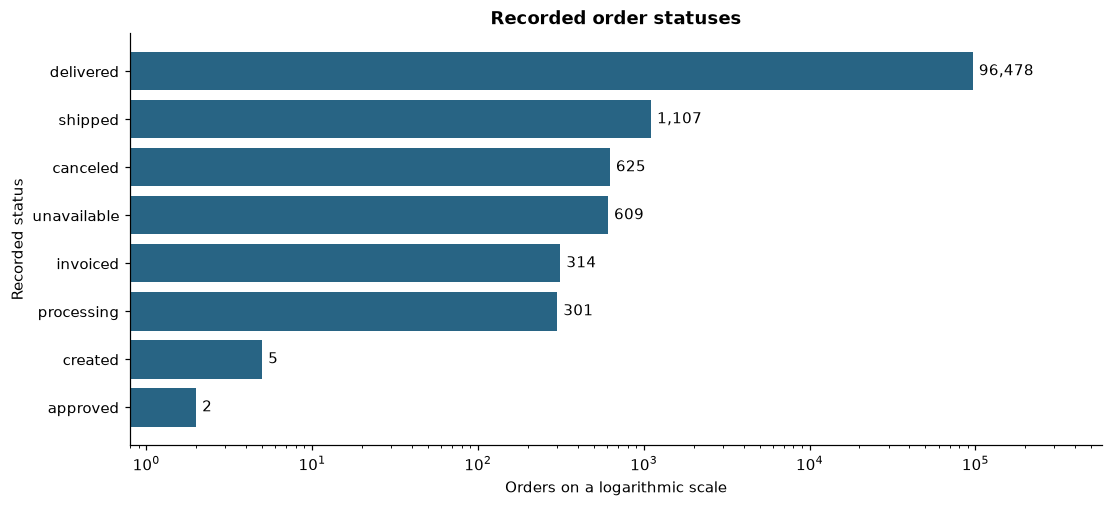

In [20]:
status_counts = order_facts["order_status"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bars = ax.barh(status_counts.index, status_counts.values, color="#286484")
ax.set_xscale("log")
ax.set_xlim(0.8, status_counts.max() * 6)
ax.bar_label(bars, labels=[f"{n:,}" for n in status_counts.values], padding=4)
ax.set(title="Recorded order statuses", xlabel="Orders on a logarithmic scale", ylabel="Recorded status")
plt.show()


**Observed finding and implication**

The delivered cohort contains 96,478 of 99,441 source orders. Smaller status groups remain relevant when choosing a later prediction-time cohort.

### 4.2 Activity over time

Count distinct orders by purchase month for all statuses and the delivered cohort. Include zero-count months in the displayed monthly index. Boundary months and sparse tail months require review before choosing reliable prediction and follow-up periods.

Changes in observed volume can reflect market activity, data coverage, or order completion. The chart alone cannot distinguish those causes.


         all_orders  delivered_with_items
2018-06        6167                  6099
2018-07        6292                  6159
2018-08        6512                  6351
2018-09          16                     0
2018-10           4                     0


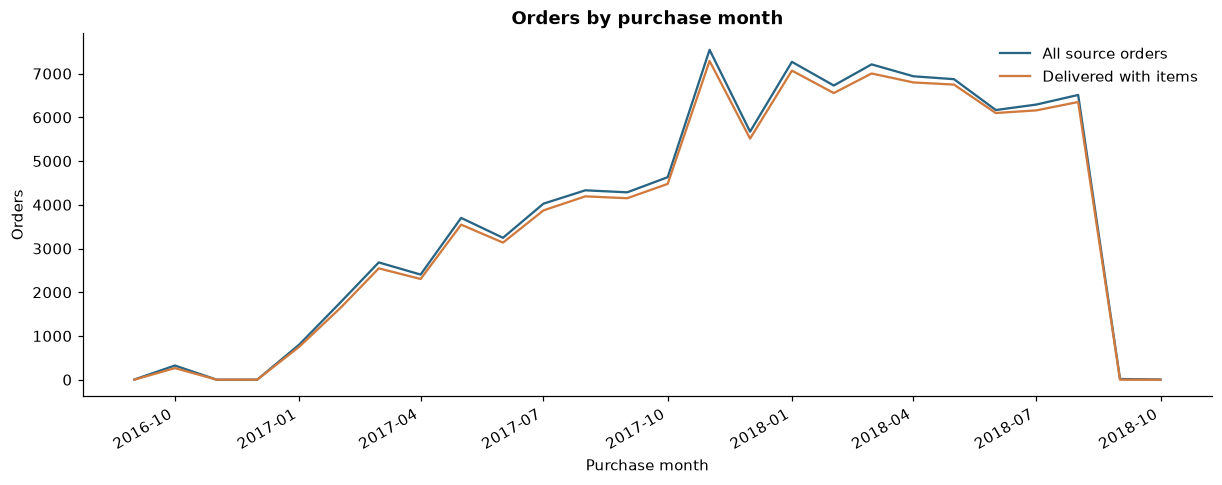

In [21]:
monthly_all = order_facts.groupby(
    order_facts["order_purchase_timestamp"].dt.to_period("M")
).size()
monthly_delivered = analysis_orders.groupby(
    analysis_orders["order_purchase_timestamp"].dt.to_period("M")
).size()
month_index = pd.period_range(monthly_all.index.min(), monthly_all.index.max(), freq="M")
monthly_activity = pd.DataFrame({
    "all_orders": monthly_all.reindex(month_index, fill_value=0),
    "delivered_with_items": monthly_delivered.reindex(month_index, fill_value=0),
})
fig, ax = plt.subplots(figsize=(11, 4.3), layout="constrained")
ax.plot(month_index.to_timestamp(), monthly_activity["all_orders"], label="All source orders", color="#286484")
ax.plot(month_index.to_timestamp(), monthly_activity["delivered_with_items"], label="Delivered with items", color="#d17a3e")
ax.set(title="Orders by purchase month", xlabel="Purchase month", ylabel="Orders")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.show()
print(monthly_activity.tail(5).to_string())


**Observed finding and implication**

The snapshot contains 6,512 source orders in August 2018, then 16 in September and 4 in October. The latter two months contain no delivered orders in this cohort. Treat the sparse tail as a coverage concern when choosing the modeling interval, rather than interpreting it as an established collapse in demand.

### 4.3 Merchandise value and freight distributions

Summarize the complete cohort with percentiles. Display the full merchandise-value range on a logarithmic horizontal scale, then compare freight against merchandise value using a deterministic sample for readability. The summaries use all eligible orders.

Scatter sampling is for display only. High-value observations remain in the data. A broad right tail may motivate transformations or robust methods during feature engineering.


       items_value  freight_total  item_count
count     96478.00       96478.00    96478.00
mean        137.04          22.79        1.14
std         209.05          21.56        0.54
min           0.85           0.00        1.00
50%          86.57          17.17        1.00
90%         269.00          39.38        1.00
95%         399.00          54.78        2.00
99%         990.00         104.24        3.00
max       13440.00        1794.96       21.00


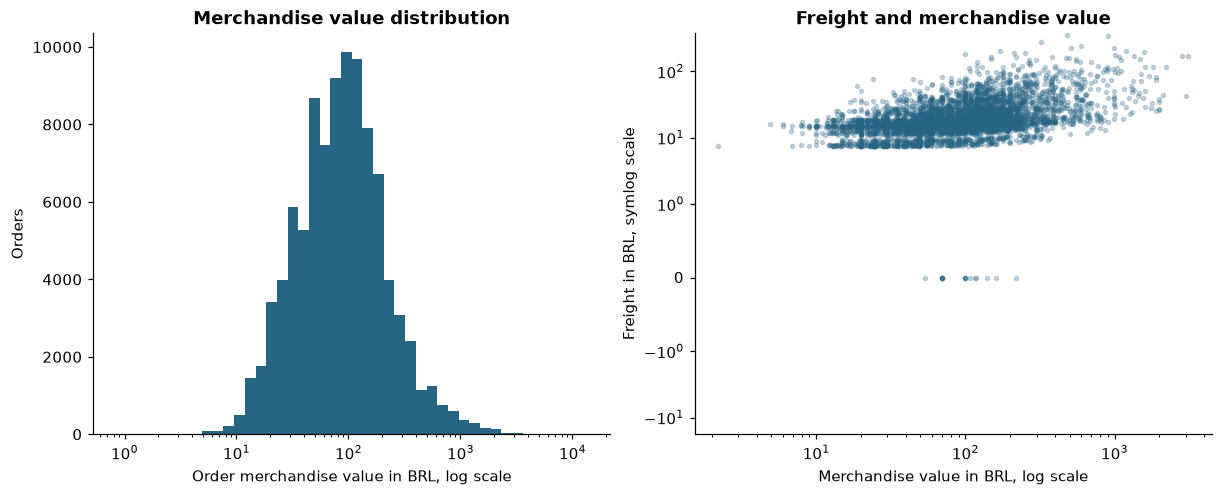

In [22]:
spend_summary = analysis_orders[["items_value", "freight_total", "item_count"]].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
).round(2)
print(spend_summary.to_string())
eda_metrics["median_merchandise_value"] = float(analysis_orders["items_value"].median())
eda_metrics["p99_merchandise_value"] = float(analysis_orders["items_value"].quantile(0.99))

sample_orders = analysis_orders.sample(n=min(5000, len(analysis_orders)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
spend_bins = np.geomspace(analysis_orders["items_value"].min(), analysis_orders["items_value"].max(), 45)
axes[0].hist(analysis_orders["items_value"], bins=spend_bins, color="#286484")
axes[0].set_xscale("log")
axes[0].set(title="Merchandise value distribution", xlabel="Order merchandise value in BRL, log scale", ylabel="Orders")
axes[1].scatter(sample_orders["items_value"], sample_orders["freight_total"], s=7, alpha=0.25, color="#286484")
axes[1].set_xscale("log")
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set(title="Freight and merchandise value", xlabel="Merchandise value in BRL, log scale", ylabel="Freight in BRL, symlog scale")
plt.show()


**Observed finding and implication**

Median merchandise value is BRL 86.57, while the 99th percentile is BRL 990.00. The broad range supports evaluating a log transform or robust preprocessing later. The scatter uses at most 5,000 orders with random seed 42 for readability, while statistics use the full cohort.

### 4.4 Customer activity and observed repeat purchases

Group orders by the stable customer identity. Count distinct delivered orders and sum merchandise value once per order.

The observed repeat-buyer share counts customers with at least two delivered orders anywhere in the observed cohort. Customers have different observation lengths, so this percentage is a descriptive snapshot and requires a follow-up adjustment before interpreting a future repeat-purchase target.

For repeat buyers, calculate the interval between the first and second observed delivered purchases. A zero-day interval can represent distinct orders placed on the same day.


Observed repeat-buyer share: 3.00%
Median first-to-second purchase interval: 28.98 days


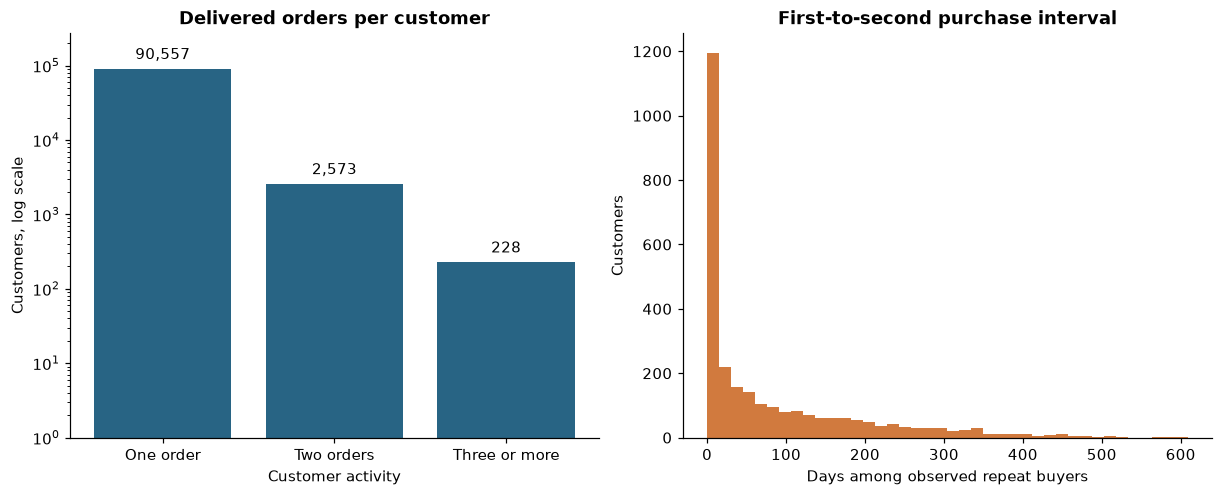

In [23]:
customer_activity = analysis_orders.groupby("customer_unique_id").agg(
    delivered_orders=("order_id", "nunique"),
    merchandise_spend=("items_value", "sum"),
    first_purchase=("order_purchase_timestamp", "min"),
    last_purchase=("order_purchase_timestamp", "max"),
)
repeat_buyers = customer_activity["delivered_orders"].ge(2)
eda_metrics["observed_repeat_buyers"] = int(repeat_buyers.sum())
eda_metrics["observed_repeat_buyer_percent"] = float(100 * repeat_buyers.mean())

ordered_purchases = analysis_orders.sort_values(
    ["customer_unique_id", "order_purchase_timestamp", "order_id"]
).copy()
ordered_purchases["purchase_number"] = ordered_purchases.groupby("customer_unique_id").cumcount()
second_purchase_times = ordered_purchases.loc[
    ordered_purchases["purchase_number"].eq(1)
].set_index("customer_unique_id")["order_purchase_timestamp"]
customer_activity["second_purchase"] = second_purchase_times
repeat_intervals = (
    customer_activity["second_purchase"] - customer_activity["first_purchase"]
).dt.total_seconds().div(86400).dropna()
eda_metrics["median_first_to_second_days"] = float(repeat_intervals.median())

activity_groups = pd.Series({
    "One order": int(customer_activity["delivered_orders"].eq(1).sum()),
    "Two orders": int(customer_activity["delivered_orders"].eq(2).sum()),
    "Three or more": int(customer_activity["delivered_orders"].ge(3).sum()),
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
bars = axes[0].bar(activity_groups.index, activity_groups.values, color="#286484")
axes[0].set_yscale("log")
axes[0].set_ylim(1, activity_groups.max() * 3)
axes[0].bar_label(bars, labels=[f"{n:,}" for n in activity_groups], padding=4)
axes[0].set(title="Delivered orders per customer", xlabel="Customer activity", ylabel="Customers, log scale")
axes[1].hist(repeat_intervals, bins=40, color="#d17a3e")
axes[1].set(title="First-to-second purchase interval", xlabel="Days among observed repeat buyers", ylabel="Customers")
plt.show()
print(f"Observed repeat-buyer share: {eda_metrics['observed_repeat_buyer_percent']:.2f}%")
print(f"Median first-to-second purchase interval: {repeat_intervals.median():.2f} days")


**Observed finding and implication**

There are 93,358 customers and 2,801 observed repeat buyers, or 3.00 percent. Among observed repeat buyers, the median first-to-second interval is 28.98 days. Different history lengths make the follow-up analysis necessary before using a repeat label.

### 4.5 Product demand, categories, and interaction sparsity

Deduplicate customer-product pairs when measuring implicit interactions. Purchases of multiple units remain in item demand counts, but contribute one observed pair to the binary interaction count.

Measure demand concentration through the cumulative share of observed customer-product pairs. Category popularity uses source item rows from the delivered cohort.

Sparsity is calculated from counts only. Missing customer-product pairs are unobserved interactions. The dataset does not establish dislike or exposure for those pairs.


Interaction sparsity: 99.99668%
Products bought by one observed customer: 59.52%


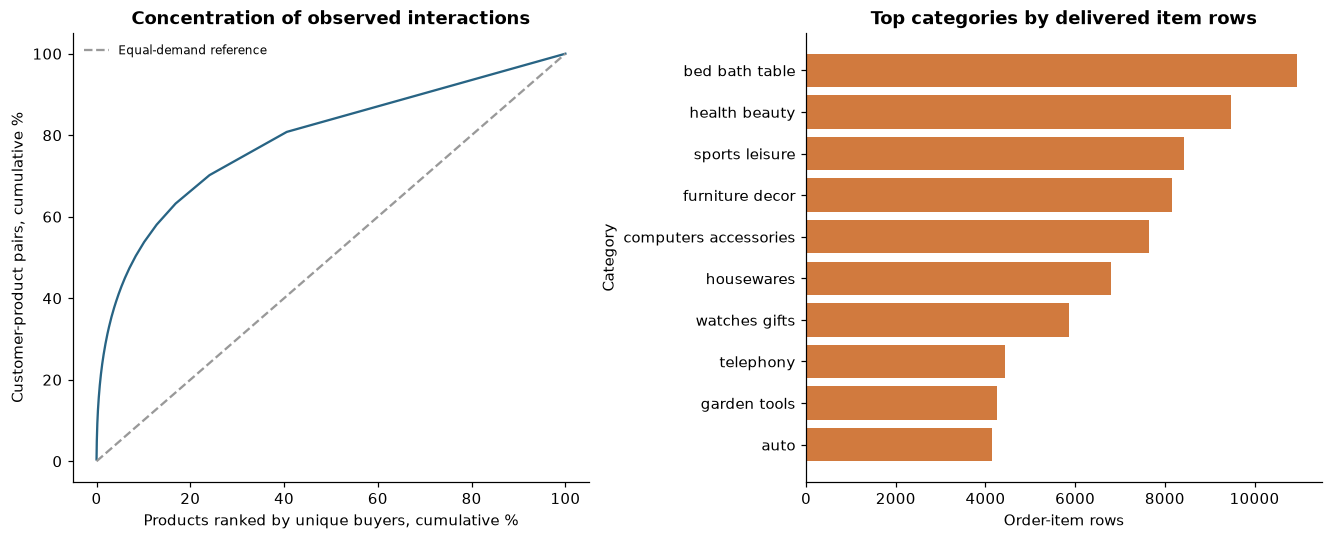

In [24]:
customer_product_pairs = analysis_items[["customer_unique_id", "product_id"]].drop_duplicates()
buyers_per_product = customer_product_pairs.groupby("product_id").size().sort_values(ascending=False)
observed_users = int(customer_product_pairs["customer_unique_id"].nunique())
observed_products = int(customer_product_pairs["product_id"].nunique())
interaction_sparsity = 1 - len(customer_product_pairs) / (observed_users * observed_products)
single_buyer_products = int(buyers_per_product.eq(1).sum())
eda_metrics.update({
    "observed_products": observed_products,
    "unique_customer_product_pairs": int(len(customer_product_pairs)),
    "interaction_sparsity_percent": float(100 * interaction_sparsity),
    "single_buyer_product_percent": float(100 * single_buyer_products / observed_products),
    "top_ten_product_interaction_percent": float(100 * buyers_per_product.head(10).sum() / buyers_per_product.sum()),
})

cumulative_demand = buyers_per_product.cumsum() / buyers_per_product.sum()
product_fraction = np.arange(1, len(buyers_per_product) + 1) / len(buyers_per_product)
top_categories = analysis_items["category_label"].value_counts().head(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axes[0].plot(100 * product_fraction, 100 * cumulative_demand.values, color="#286484")
axes[0].plot([0, 100], [0, 100], "--", color="#999999", label="Equal-demand reference")
axes[0].set(title="Concentration of observed interactions", xlabel="Products ranked by unique buyers, cumulative %", ylabel="Customer-product pairs, cumulative %")
axes[0].legend(frameon=False, fontsize=8)
axes[1].barh(top_categories.index.str.replace("_", " "), top_categories.values, color="#d17a3e")
axes[1].set(title="Top categories by delivered item rows", xlabel="Order-item rows", ylabel="Category")
plt.show()
print(f"Interaction sparsity: {100 * interaction_sparsity:.5f}%")
print(f"Products bought by one observed customer: {100 * single_buyer_products / observed_products:.2f}%")


**Observed finding and implication**

The cohort has 99,785 distinct customer-product pairs and 32,216 products. Interaction sparsity is 99.99668 percent, and 59.52 percent of products have just one observed buyer. Compare collaborative methods with popularity and content-based fallbacks, and report the eligible recommendation cohort.

### 4.6 Regional order volume

Count distinct delivered orders by customer state. Print the leading state's share and review the dominance of large groups before making later subgroup comparisons.

Geographic order counts describe this marketplace sample. They do not measure population demand or establish that location causes purchasing behavior.


Leading state: SP
Leading state's order share: 41.98%


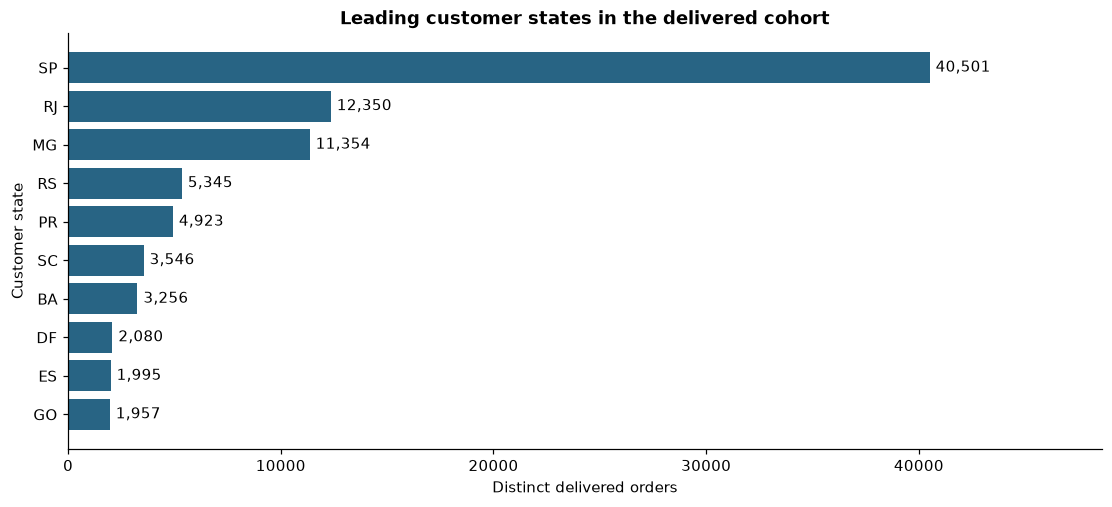

In [25]:
state_orders = analysis_orders.groupby("customer_state")["order_id"].nunique().sort_values(ascending=False)
eda_metrics["leading_state_order_percent"] = float(100 * state_orders.iloc[0] / len(analysis_orders))
top_states = state_orders.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bars = ax.barh(top_states.index, top_states.values, color="#286484")
ax.bar_label(bars, labels=[f"{n:,}" for n in top_states], padding=4)
ax.set_xlim(0, top_states.max() * 1.2)
ax.set(title="Leading customer states in the delivered cohort", xlabel="Distinct delivered orders", ylabel="Customer state")
plt.show()
print(f"Leading state: {state_orders.index[0]}")
print(f"Leading state's order share: {eda_metrics['leading_state_order_percent']:.2f}%")


**Observed finding and implication**

SP accounts for 41.98 percent of delivered orders in the cohort. Compare later error rates together with subgroup sample sizes so a dominant region does not hide weak performance elsewhere.

### 4.7 Review scores and delivery experience

Use each order's earliest eligible review prepared in the cleaning section. Compare the share of scores 1 to 3 between orders delivered after their estimated calendar date and orders delivered by that date.

Delivery duration uses purchase-to-customer-delivery time. Compare normalized calendar dates for lateness so that delivery on the estimated day is counted as on time. Missing dates or unavailable reviews are excluded only from the applicable comparison, with cohort sizes reported.

Review scores reflect the overall recorded order experience. This comparison describes association and does not prove that delivery timing causes a score.


                      reviewed_orders  score_1_to_3_share
delivery_group                                           
After estimated date             6381            0.732017
By estimated date               89440            0.173189
Delivered orders without an eligible review: 649


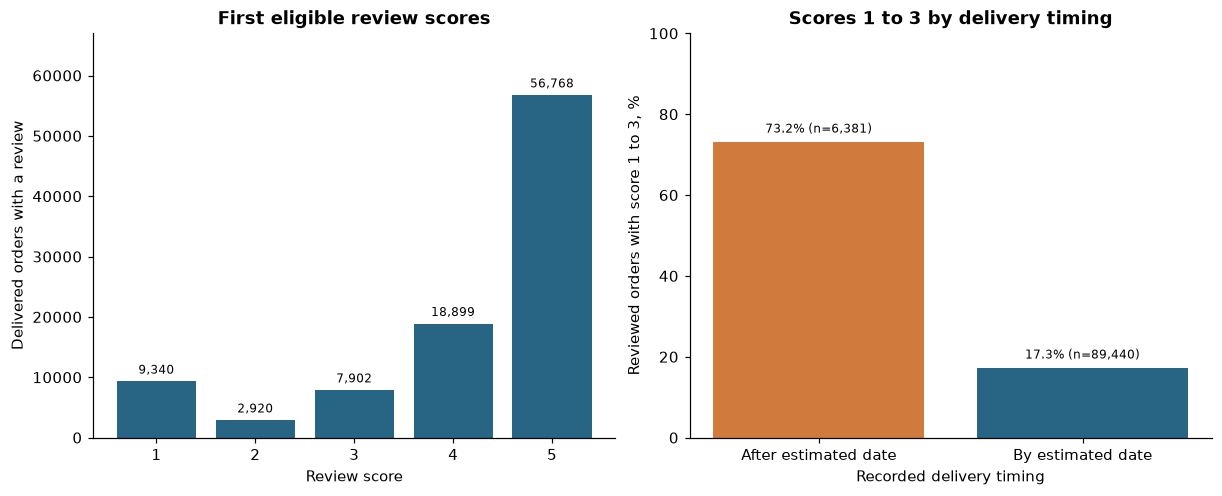

In [26]:
analysis_orders["delivery_days"] = (
    analysis_orders["order_delivered_customer_date"] - analysis_orders["order_purchase_timestamp"]
).dt.total_seconds().div(86400)

reviewed_orders = analysis_orders.loc[analysis_orders["has_eligible_review"]].copy()
score_counts = reviewed_orders["first_review_score"].value_counts().reindex(range(1, 6), fill_value=0)
delivery_comparison = reviewed_orders.loc[
    reviewed_orders["order_delivered_customer_date"].notna()
    & reviewed_orders["order_estimated_delivery_date"].notna()
    & reviewed_orders["delivery_days"].ge(0)
].copy()
delivery_comparison["delivery_group"] = np.where(
    delivery_comparison["order_delivered_customer_date"].dt.normalize()
    > delivery_comparison["order_estimated_delivery_date"].dt.normalize(),
    "After estimated date", "By estimated date",
)
delivery_comparison["score_1_to_3"] = delivery_comparison["first_review_score"].le(3)
delivery_review_summary = delivery_comparison.groupby("delivery_group").agg(
    reviewed_orders=("order_id", "size"),
    score_1_to_3_share=("score_1_to_3", "mean"),
)
eda_metrics["reviewed_delivered_orders"] = int(len(reviewed_orders))
eda_metrics["delivery_review_comparison_orders"] = int(len(delivery_comparison))
eda_metrics["median_delivery_days"] = float(analysis_orders["delivery_days"].median())
eda_metrics["late_score_1_to_3_percent"] = float(
    100 * delivery_review_summary.loc["After estimated date", "score_1_to_3_share"]
)
eda_metrics["on_time_score_1_to_3_percent"] = float(
    100 * delivery_review_summary.loc["By estimated date", "score_1_to_3_share"]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
bars = axes[0].bar(score_counts.index.astype(str), score_counts.values, color="#286484")
axes[0].bar_label(bars, labels=[f"{n:,}" for n in score_counts], padding=3, fontsize=8)
axes[0].set_ylim(0, score_counts.max() * 1.18)
axes[0].set(title="First eligible review scores", xlabel="Review score", ylabel="Delivered orders with a review")
rates = 100 * delivery_review_summary["score_1_to_3_share"]
bars = axes[1].bar(rates.index, rates.values, color=["#d17a3e", "#286484"])
axes[1].bar_label(bars, labels=[f"{v:.1f}% (n={n:,})" for v, n in zip(rates, delivery_review_summary["reviewed_orders"])], padding=4, fontsize=8)
axes[1].set_ylim(0, 100)
axes[1].set(title="Scores 1 to 3 by delivery timing", xlabel="Recorded delivery timing", ylabel="Reviewed orders with score 1 to 3, %")
plt.show()
print(delivery_review_summary.to_string())
print(f"Delivered orders without an eligible review: {int((~analysis_orders['has_eligible_review']).sum())}")


**Observed finding and implication**

The comparison includes 95,821 reviewed orders with usable delivery timing. Scores 1 to 3 occur in 73.20 percent of late cases and 17.32 percent of on-time cases. This is a strong descriptive association. Confounding, review selection, and review timing prevent a causal conclusion. Review scores describe the order experience and require care before use as product-preference labels.

### 4.8 Numeric associations

Calculate Pearson correlations at one row per delivered order. Pairwise available values are used, so sample sizes differ where a review or delivery date is missing. Print non-missing counts alongside the heatmap.

Correlation is descriptive and can be sensitive to outliers. Review and realized delivery fields may be unavailable at an earlier prediction date, so their presence in this plot does not make them eligible model inputs.


Non-missing observations per field:
items_value           96478
freight_total         96478
item_count            96478
delivery_days         96470
first_review_score    95829


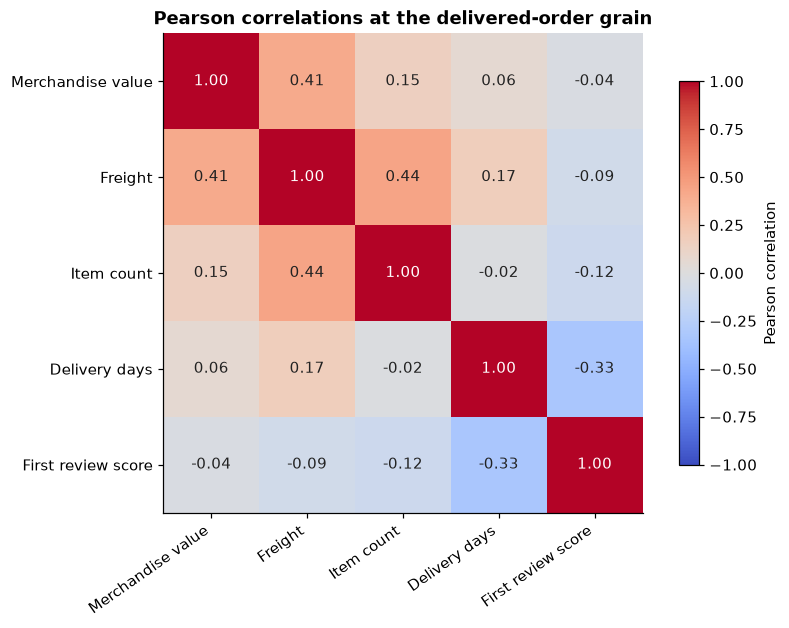

In [27]:
correlation_columns = ["items_value", "freight_total", "item_count", "delivery_days", "first_review_score"]
numeric_correlations = analysis_orders[correlation_columns].corr(method="pearson")
labels = ["Merchandise value", "Freight", "Item count", "Delivery days", "First review score"]
fig, ax = plt.subplots(figsize=(8, 5.6), layout="constrained")
image = ax.imshow(numeric_correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(labels)), labels=labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
for row in range(len(labels)):
    for column in range(len(labels)):
        value = numeric_correlations.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.65 else "#222222")
ax.set_title("Pearson correlations at the delivered-order grain")
fig.colorbar(image, ax=ax, label="Pearson correlation", shrink=0.8)
plt.show()
print("Non-missing observations per field:")
print(analysis_orders[correlation_columns].notna().sum().to_string())


**Observed finding and implication**

Delivery duration and the first review score have a negative Pearson correlation of approximately -0.33 in this cohort. Merchandise value and freight correlate at approximately 0.41. Evaluate skew, temporal availability, and missingness before turning an association into a feature choice.

### 4.9 Candidate repeat-purchase windows

Examine 30, 60, and 90-day follow-up windows from each customer's first observed delivered purchase. Include a customer in a window's denominator only when its end falls on or before the final observed delivered purchase timestamp.

A repeat means a second distinct delivered order within that window, including a same-day second order. Customers whose second order falls later count as non-repeaters within the stated window.

The last observed delivered purchase is a provisional coverage boundary. Verify data completeness around that boundary when defining the model target. Eligibility cohorts differ between windows, so the percentages reflect both the horizon and cohort composition. These summaries are feasibility evidence and do not establish the final target or its performance.


 window_days  eligible_customers  repeat_customers  repeat_percent
          30               86772              1373        1.582308
          60               81203              1584        1.950667
          90               75320              1714        2.275624
Provisional delivered-purchase coverage end: 2018-08-29 15:00:37


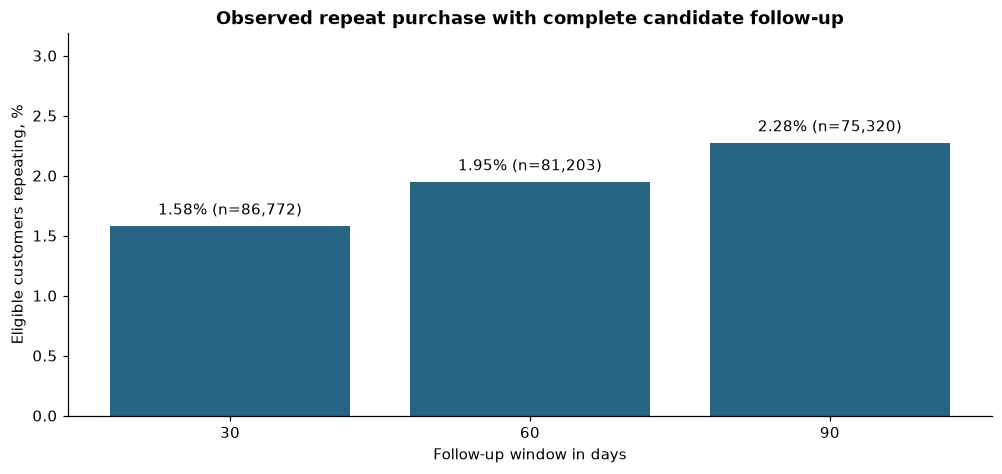

In [28]:
observed_delivery_purchase_end = analysis_orders["order_purchase_timestamp"].max()
followup_rows = []

for days in [30, 60, 90]:
    full_followup = (
        customer_activity["first_purchase"] + pd.Timedelta(days=days)
        <= observed_delivery_purchase_end
    )
    eligible = customer_activity.loc[full_followup]
    repeat_within_window = (
        eligible["second_purchase"].notna()
        & (eligible["second_purchase"] <= eligible["first_purchase"] + pd.Timedelta(days=days))
    )
    followup_rows.append({
        "window_days": days,
        "eligible_customers": int(len(eligible)),
        "repeat_customers": int(repeat_within_window.sum()),
        "repeat_percent": float(100 * repeat_within_window.mean()),
    })

followup_summary = pd.DataFrame(followup_rows)
row_90 = followup_summary.loc[followup_summary["window_days"].eq(90)].iloc[0]
eda_metrics["followup_90_eligible_customers"] = int(row_90["eligible_customers"])
eda_metrics["followup_90_repeat_customers"] = int(row_90["repeat_customers"])
eda_metrics["followup_90_repeat_percent"] = float(row_90["repeat_percent"])

fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bars = ax.bar(followup_summary["window_days"].astype(str), followup_summary["repeat_percent"], color="#286484")
ax.bar_label(bars, labels=[
    f"{rate:.2f}% (n={count:,})"
    for rate, count in zip(followup_summary["repeat_percent"], followup_summary["eligible_customers"])
], padding=5)
ax.set_ylim(0, followup_summary["repeat_percent"].max() * 1.4)
ax.set(title="Observed repeat purchase with complete candidate follow-up", xlabel="Follow-up window in days", ylabel="Eligible customers repeating, %")
plt.show()
print(followup_summary.to_string(index=False))
print(f"Provisional delivered-purchase coverage end: {observed_delivery_purchase_end}")


**Observed finding and implication**

The provisional 90-day cohort contains 75,320 customers with 1,714 observed repeaters, or 2.28 percent. A constant non-repeat classification would have arithmetic accuracy of 97.72 percent in this cohort, showing why accuracy alone is insufficient. The final target still needs a verified coverage boundary and a prediction-date definition.

### EDA evidence summary

The following table collects measured values used to write the interpretation and reference notes. Percentages use the explicit cohorts defined in the analysis sections.


In [29]:
print(pd.Series(eda_metrics, name="value").to_string())

source_orders                           99441.000000
delivered_orders_with_items             96478.000000
analysis_item_rows                     110197.000000
analysis_customers                      93358.000000
median_merchandise_value                   86.575000
p99_merchandise_value                     990.000000
observed_repeat_buyers                   2801.000000
observed_repeat_buyer_percent               3.000278
median_first_to_second_days                28.980197
observed_products                       32216.000000
unique_customer_product_pairs           99785.000000
interaction_sparsity_percent               99.996682
single_buyer_product_percent               59.520114
top_ten_product_interaction_percent         3.242972
leading_state_order_percent                41.979519
reviewed_delivered_orders               95829.000000
delivery_review_comparison_orders       95821.000000
median_delivery_days                       10.217477
late_score_1_to_3_percent                  73.

### EDA conclusions and decisions for the next topic

- Most customers have one observed delivered purchase, and customer-product interactions are extremely sparse. Establish popularity baselines and explicit cold-start behavior before judging collaborative filtering.
- Repeat purchase is a minority outcome in the candidate follow-up cohorts. Use class-sensitive metrics, temporal validation, and explicit eligibility counts.
- The final sparse months require a defensible data-coverage boundary. Target construction must distinguish incomplete follow-up from a fully observed non-repeat outcome.
- Spending spans a broad range. Assess transformations and fit statistical preprocessing only on training data.
- Delivery experience and review scores are associated. Use reviews as carefully timed order-experience signals rather than assuming each order review directly rates every product.
- Geographic volume is concentrated. Any later subgroup analysis must report cohort sizes alongside error rates.
- The next topic will define historical customer snapshots, features, repeat-purchase labels, recommendation interactions, and chronological evaluation splits.

**Topic commit message** — `feat: complete Olist exploratory analysis and document findings`.

The notebook, reference notes, README, environment requirements, and ignore rules form this contribution. The local environment is ignored. Current raw CSV tracking is documented in the README.

## 5 Historical features targets and chronological partitions

Define two tasks with separate evaluation cohorts.

For retention, score an existing customer 30 days after their first observed item-bearing placed order. Predict at least one further item-bearing order in the next 90 days. This defines a fixed-age retention decision. Scores from a model trained on this design apply to that decision point.

For recommendations, learn from purchases placed before a global cutoff and evaluate discovery of previously unseen products in a future 30-day window. Report cold-customer, unseen-catalog, and repeated-product coverage separately.

An item-bearing placed order is an order with recorded line items. The label describes another placed order, including a later-canceled order if it has items. It does not depend on eventual delivery status. This differs from EDA's retrospective delivered-order cohort.

The late sparse months identified by EDA motivate a working observation boundary of 1 September 2018, exclusive. This boundary is an explicit modeling assumption. A static snapshot cannot prove historical completeness or recover all later edits. Sensitivity to target and coverage choices should be discussed with final results.


In [30]:
COVERAGE_END = pd.Timestamp("2018-09-01")
SNAPSHOT_START = pd.Timestamp("2017-01-01")
CUSTOMER_AGE_DAYS = 30
REPEAT_HORIZON_DAYS = 90
RETENTION_VALIDATION_START = pd.Timestamp("2017-11-01")
RETENTION_TEST_START = pd.Timestamp("2018-04-01")

REC_VALIDATION_CUTOFF = pd.Timestamp("2018-04-01")
REC_TEST_CUTOFF = pd.Timestamp("2018-06-01")
REC_HORIZON_DAYS = 30

placed_order_events = order_facts.loc[
    order_facts["has_item_records"]
    & order_facts["order_purchase_timestamp"].lt(COVERAGE_END)
].copy()

assert placed_order_events["order_id"].is_unique
assert placed_order_events["customer_unique_id"].notna().all()

print(f"Item-bearing placed orders before the coverage boundary: {len(placed_order_events):,}")
print(f"Working coverage end, exclusive: {COVERAGE_END}")


Item-bearing placed orders before the coverage boundary: 98,665
Working coverage end, exclusive: 2018-09-01 00:00:00


### 5.1 Customer snapshots and future outcomes

Assign one snapshot per customer at first observed placed purchase plus 30 days. Keep snapshots from the stated start date only when their entire 90-day outcome window ends before the working observation boundary.

A positive label requires another order strictly after the snapshot and on or before its outcome end. Orders at or before the snapshot belong to history. Customers with insufficient follow-up are excluded before splitting. This target concerns future customer orders, independently of whether they reorder the same product.


In [31]:
first_observed_purchase = placed_order_events.groupby(
    "customer_unique_id"
)["order_purchase_timestamp"].min()

customer_snapshots = first_observed_purchase.rename("first_observed_purchase_at").to_frame()
customer_snapshots["snapshot_at"] = (
    customer_snapshots["first_observed_purchase_at"]
    + pd.Timedelta(days=CUSTOMER_AGE_DAYS)
)
customer_snapshots["outcome_end"] = (
    customer_snapshots["snapshot_at"] + pd.Timedelta(days=REPEAT_HORIZON_DAYS)
)

complete_snapshot_mask = (
    customer_snapshots["snapshot_at"].ge(SNAPSHOT_START)
    & customer_snapshots["outcome_end"].lt(COVERAGE_END)
)
eligible_snapshots = customer_snapshots.loc[complete_snapshot_mask].reset_index()

snapshot_order_events = placed_order_events.merge(
    eligible_snapshots,
    on="customer_unique_id",
    how="inner",
    validate="many_to_one",
)

history_order_events = snapshot_order_events.loc[
    snapshot_order_events["order_purchase_timestamp"].le(snapshot_order_events["snapshot_at"])
].copy()
future_order_events = snapshot_order_events.loc[
    snapshot_order_events["order_purchase_timestamp"].gt(snapshot_order_events["snapshot_at"])
    & snapshot_order_events["order_purchase_timestamp"].le(snapshot_order_events["outcome_end"])
].copy()

future_counts = future_order_events.groupby("customer_unique_id")["order_id"].nunique()
eligible_snapshots["future_order_count"] = (
    eligible_snapshots["customer_unique_id"].map(future_counts).fillna(0).astype(int)
)
eligible_snapshots["repeat_90d"] = eligible_snapshots["future_order_count"].gt(0).astype(int)

snapshot_summary = pd.DataFrame([
    {"measure": "Customers with an observed item-bearing order", "count": len(customer_snapshots)},
    {"measure": "Snapshots meeting start and complete-follow-up rules", "count": len(eligible_snapshots)},
    {"measure": "Eligible snapshots with a future repeat order", "count": int(eligible_snapshots["repeat_90d"].sum())},
])
print(snapshot_summary.to_string(index=False))


                                             measure  count
       Customers with an observed item-bearing order  95420
Snapshots meeting start and complete-follow-up rules  71105
       Eligible snapshots with a future repeat order    665


### 5.2 Purchase history features

Aggregate only orders at or before each snapshot. Use order-level facts for spending so item and payment multiplicity cannot inflate monetary features. Use historical item rows for product and seller breadth.

Recency measures days since the latest historical placed order. Frequency is distinct historical orders. Monetary value is historical merchandise spend excluding freight. Age is fixed by design, so a constant customer-age feature is omitted.

State comes from the earliest historical order. Product and seller identifiers are used for grouping and counting, and are excluded from the predictor lists.


In [32]:
history_order_events = history_order_events.sort_values(
    ["customer_unique_id", "order_purchase_timestamp", "order_id"]
)

purchase_features = history_order_events.groupby("customer_unique_id").agg(
    historical_order_count=("order_id", "nunique"),
    merchandise_spend=("items_value", "sum"),
    average_order_value=("items_value", "mean"),
    historical_freight=("freight_total", "sum"),
    latest_historical_purchase_at=("order_purchase_timestamp", "max"),
    customer_state=("customer_state", "first"),
).reset_index()

history_item_events = purchase_events.merge(
    history_order_events[["order_id", "customer_unique_id", "snapshot_at"]],
    on=["order_id", "customer_unique_id"],
    how="inner",
    validate="many_to_one",
)
breadth_features = history_item_events.groupby("customer_unique_id").agg(
    distinct_products=("product_id", "nunique"),
    distinct_sellers=("seller_id", "nunique"),
).reset_index()

retention_dataset = eligible_snapshots.merge(
    purchase_features, on="customer_unique_id", how="left", validate="one_to_one"
).merge(
    breadth_features, on="customer_unique_id", how="left", validate="one_to_one"
)
retention_dataset["recency_days"] = (
    retention_dataset["snapshot_at"] - retention_dataset["latest_historical_purchase_at"]
).dt.total_seconds().div(86400)
retention_dataset["freight_ratio"] = (
    retention_dataset["historical_freight"] / retention_dataset["merchandise_spend"]
)
print(retention_dataset[
    ["historical_order_count", "distinct_products", "merchandise_spend", "recency_days"]
].describe().round(3).to_string())


       historical_order_count  distinct_products  merchandise_spend  recency_days
count               71105.000          71105.000          71105.000     71105.000
mean                    1.018              1.054            139.437        29.915
std                     0.142              0.269            210.572         1.243
min                     1.000              1.000              0.850         0.015
25%                     1.000              1.000             46.990        30.000
50%                     1.000              1.000             89.000        30.000
75%                     1.000              1.000            150.000        30.000
max                     6.000              7.000          13440.000        30.000


### 5.3 Reviews and deliveries available by the snapshot

Use the first eligible review only if its recorded answer is at or before the snapshot. Include a completed delivery duration only when customer delivery is recorded by that date and at or after purchase.

Aggregate known event counts and their means. Leave unavailable mean scores and durations missing. Their imputers will be fitted on training data in the baseline topic. Availability maxima remain audit columns, outside the model inputs.

Checkout amounts, recorded product identities, and review-answer timestamps serve as availability proxies in this static dataset. The snapshot cannot reconstruct later corrections to source records.


In [33]:
known_reviews = (
    history_order_events["first_review_available_at"].notna()
    & history_order_events["first_review_available_at"].le(history_order_events["snapshot_at"])
)
known_deliveries = (
    history_order_events["order_delivered_customer_date"].notna()
    & history_order_events["order_delivered_customer_date"].le(history_order_events["snapshot_at"])
    & history_order_events["order_delivered_customer_date"].ge(
        history_order_events["order_purchase_timestamp"]
    )
)

history_order_events["known_review_score"] = (
    history_order_events["first_review_score"].where(known_reviews)
)
history_order_events["known_review_available_at"] = (
    history_order_events["first_review_available_at"].where(known_reviews)
)
history_order_events["known_delivery_at"] = (
    history_order_events["order_delivered_customer_date"].where(known_deliveries)
)
history_order_events["known_delivery_days"] = (
    history_order_events["known_delivery_at"]
    - history_order_events["order_purchase_timestamp"]
).dt.total_seconds().div(86400)

known_event_features = history_order_events.groupby("customer_unique_id").agg(
    known_review_count=("known_review_score", "count"),
    mean_known_review_score=("known_review_score", "mean"),
    latest_known_review_at=("known_review_available_at", "max"),
    known_delivery_count=("known_delivery_at", "count"),
    mean_known_delivery_days=("known_delivery_days", "mean"),
    latest_known_delivery_at=("known_delivery_at", "max"),
).reset_index()

retention_dataset = retention_dataset.merge(
    known_event_features, on="customer_unique_id", how="left", validate="one_to_one"
)

retention_dataset["log1p_merchandise_spend"] = np.log1p(retention_dataset["merchandise_spend"])
retention_dataset["log1p_average_order_value"] = np.log1p(retention_dataset["average_order_value"])

RETENTION_NUMERIC_FEATURES = [
    "recency_days", "historical_order_count", "distinct_products", "distinct_sellers",
    "log1p_merchandise_spend", "log1p_average_order_value", "freight_ratio",
    "known_review_count", "mean_known_review_score",
    "known_delivery_count", "mean_known_delivery_days",
]
RETENTION_CATEGORICAL_FEATURES = ["customer_state"]
RETENTION_FEATURES = RETENTION_NUMERIC_FEATURES + RETENTION_CATEGORICAL_FEATURES

print("Predictor fields:")
print(pd.Series(RETENTION_FEATURES).to_string(index=False))
print()
print("Missing predictor values before training-fitted preprocessing:")
print(retention_dataset[RETENTION_FEATURES].isna().sum().to_string())


Predictor fields:
             recency_days
   historical_order_count
        distinct_products
         distinct_sellers
  log1p_merchandise_spend
log1p_average_order_value
            freight_ratio
       known_review_count
  mean_known_review_score
     known_delivery_count
 mean_known_delivery_days
           customer_state

Missing predictor values before training-fitted preprocessing:
recency_days                    0
historical_order_count          0
distinct_products               0
distinct_sellers                0
log1p_merchandise_spend         0
log1p_average_order_value       0
freight_ratio                   0
known_review_count              0
mean_known_review_score      5985
known_delivery_count            0
mean_known_delivery_days     5722
customer_state                  0


### 5.4 Chronological retention partitions with label maturation

Training outcomes must end before the first validation prediction date. Validation outcomes must end before the first test prediction date. The resulting gaps are deliberately excluded from this primary comparison.

Each customer contributes one snapshot and therefore belongs to at most one partition. No random train-test split or stratified time reshuffling is used. Report the remaining positive counts explicitly because the rare class limits model selection and uncertainty.


In [34]:
retention_partitions = {
    "train": retention_dataset.loc[
        retention_dataset["outcome_end"].lt(RETENTION_VALIDATION_START)
    ].copy(),
    "validation": retention_dataset.loc[
        retention_dataset["snapshot_at"].ge(RETENTION_VALIDATION_START)
        & retention_dataset["outcome_end"].lt(RETENTION_TEST_START)
    ].copy(),
    "test": retention_dataset.loc[
        retention_dataset["snapshot_at"].ge(RETENTION_TEST_START)
    ].copy(),
}

retention_split_rows = []
for partition_name, frame in retention_partitions.items():
    retention_split_rows.append({
        "partition": partition_name,
        "customers": len(frame),
        "repeat_customers": int(frame["repeat_90d"].sum()),
        "repeat_percent": round(100 * frame["repeat_90d"].mean(), 3),
        "first_snapshot": frame["snapshot_at"].min(),
        "last_snapshot": frame["snapshot_at"].max(),
        "latest_outcome_end": frame["outcome_end"].max(),
    })
retention_split_summary = pd.DataFrame(retention_split_rows)
purged_snapshot_count = len(retention_dataset) - sum(len(frame) for frame in retention_partitions.values())

X_train = retention_partitions["train"][RETENTION_FEATURES].copy()
y_train = retention_partitions["train"]["repeat_90d"].copy()
X_validation = retention_partitions["validation"][RETENTION_FEATURES].copy()
y_validation = retention_partitions["validation"]["repeat_90d"].copy()
X_test = retention_partitions["test"][RETENTION_FEATURES].copy()
y_test = retention_partitions["test"]["repeat_90d"].copy()

print(retention_split_summary.to_string(index=False))
print(f"Snapshots excluded in maturation gaps: {purged_snapshot_count:,}")


 partition  customers  repeat_customers  repeat_percent      first_snapshot       last_snapshot  latest_outcome_end
     train      14362               140           0.975 2017-01-22 23:16:47 2017-08-02 23:50:35 2017-10-31 23:50:35
validation      11768                97           0.824 2017-11-01 00:28:03 2017-12-31 23:54:03 2018-03-31 23:54:03
      test      14213               120           0.844 2018-04-01 00:07:09 2018-06-02 23:59:21 2018-08-31 23:59:21
Snapshots excluded in maturation gaps: 30,762


### 5.5 Recommendation interactions and future discovery relevance

Recommendation and retention evaluation have different row units and eligibility rules. Build recommendation history before each global cutoff and a future 30-day window with the same placed-order event policy.

Candidates are products already observed in history. Warm customers have at least one historical purchase. Relevant discovery items are future customer-product pairs that are in the historical candidate catalog and have not already been purchased by that customer.

Preserve the full future window for coverage reporting. Future new users and new catalog products remain explicit cold-start cases. Repeated-product purchases are outside this discovery protocol. No default minimum of five user interactions is imposed, and unobserved pairs are not labeled as dislikes.

After validation selects settings, final recommendation fitting may use all events before the test cutoff, including earlier validation-period events. Only test-future events remain held out. All compared methods must share the candidate and eligibility definitions.


In [35]:
placed_item_events = purchase_events.loc[
    purchase_events["order_purchase_timestamp"].lt(COVERAGE_END),
    ["customer_unique_id", "product_id", "order_id", "order_purchase_timestamp"],
].rename(columns={
    "customer_unique_id": "user",
    "product_id": "item",
    "order_purchase_timestamp": "time",
})

def build_recommendation_window(cutoff, horizon_days):
    window_end = cutoff + pd.Timedelta(days=horizon_days)
    if window_end >= COVERAGE_END:
        raise ValueError("Recommendation window must end before the working coverage boundary.")

    history = placed_item_events.loc[placed_item_events["time"].lt(cutoff)].copy()
    future = placed_item_events.loc[
        placed_item_events["time"].ge(cutoff)
        & placed_item_events["time"].lt(window_end)
    ].copy()
    history_pairs = history[["user", "item"]].drop_duplicates()
    future_pairs = future[["user", "item"]].drop_duplicates()

    annotated_pairs = future_pairs.merge(
        history_pairs.assign(seen_in_history=True),
        on=["user", "item"], how="left", validate="one_to_one",
    )
    annotated_pairs["warm_user"] = annotated_pairs["user"].isin(history_pairs["user"])
    annotated_pairs["known_item"] = annotated_pairs["item"].isin(history_pairs["item"])
    annotated_pairs["already_purchased"] = annotated_pairs["seen_in_history"].eq(True)
    relevance = annotated_pairs.loc[
        annotated_pairs["warm_user"]
        & annotated_pairs["known_item"]
        & ~annotated_pairs["already_purchased"],
        ["user", "item"],
    ].copy()

    return {
        "cutoff": cutoff, "window_end": window_end,
        "history_events": history, "history_pairs": history_pairs,
        "future_events": future, "future_pairs": annotated_pairs,
        "candidate_items": pd.Index(sorted(history_pairs["item"].unique())),
        "relevance": relevance,
    }

recommendation_partitions = {
    "validation": build_recommendation_window(REC_VALIDATION_CUTOFF, REC_HORIZON_DAYS),
    "test": build_recommendation_window(REC_TEST_CUTOFF, REC_HORIZON_DAYS),
}

recommendation_split_rows = []
for partition_name, split in recommendation_partitions.items():
    pairs = split["future_pairs"]
    recommendation_split_rows.append({
        "partition": partition_name,
        "history_pairs": len(split["history_pairs"]),
        "candidate_products": len(split["candidate_items"]),
        "future_customers": int(pairs["user"].nunique()),
        "future_unique_pairs": len(pairs),
        "cold_customer_pairs": int((~pairs["warm_user"]).sum()),
        "unseen_catalog_pairs": int((~pairs["known_item"]).sum()),
        "already_purchased_pairs": int(pairs["already_purchased"].sum()),
        "eligible_relevance_pairs": len(split["relevance"]),
        "eligible_ranking_customers": int(split["relevance"]["user"].nunique()),
    })
recommendation_split_summary = pd.DataFrame(recommendation_split_rows)
print(recommendation_split_summary.to_string(index=False))
print("Coverage categories can overlap. Eligibility applies all three conditions together.")


 partition  history_pairs  candidate_products  future_customers  future_unique_pairs  cold_customer_pairs  unseen_catalog_pairs  already_purchased_pairs  eligible_relevance_pairs  eligible_ranking_customers
validation          68203               22964              6878                 7210                 7023                  2497                       26                        97                          90
      test          82461               26895              6121                 6394                 6187                  2243                       29                       102                          97
Coverage categories can overlap. Eligibility applies all three conditions together.


### 5.6 Validate feature availability targets and partition boundaries

Check each customer's latest contributing purchase, review answer, and delivery against its snapshot. Verify the future label interval, complete follow-up, disjoint customer sets, and label maturation across retention partitions.

Independently check label counts for a deterministic sample of customers directly against the source order events. Validate ranking relevance against history and candidates. Model matrices must contain only the explicit predictor list, excluding identifiers, target counts, and audit timestamps.

Imputers, encoders, scaling, class weights, sampling, and model fitting are deferred to the baseline topic and will use training data only.


In [36]:
assert retention_dataset["customer_unique_id"].is_unique
assert len(retention_dataset) == len(eligible_snapshots)
assert retention_dataset["outcome_end"].lt(COVERAGE_END).all()
assert retention_dataset["latest_historical_purchase_at"].le(retention_dataset["snapshot_at"]).all()

for audit_column in ["latest_known_review_at", "latest_known_delivery_at"]:
    observed = retention_dataset[audit_column].notna()
    assert retention_dataset.loc[observed, audit_column].le(
        retention_dataset.loc[observed, "snapshot_at"]
    ).all()

assert future_order_events["order_purchase_timestamp"].gt(future_order_events["snapshot_at"]).all()
assert future_order_events["order_purchase_timestamp"].le(future_order_events["outcome_end"]).all()
assert retention_dataset["historical_order_count"].ge(1).all()
assert retention_dataset["recency_days"].ge(0).all()

for partition_name, frame in retention_partitions.items():
    assert not frame.empty, partition_name
    assert set(frame["repeat_90d"].unique()) == {0, 1}, partition_name

train_ids = set(retention_partitions["train"]["customer_unique_id"])
validation_ids = set(retention_partitions["validation"]["customer_unique_id"])
test_ids = set(retention_partitions["test"]["customer_unique_id"])
assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)
assert retention_partitions["train"]["outcome_end"].max() < retention_partitions["validation"]["snapshot_at"].min()
assert retention_partitions["validation"]["outcome_end"].max() < retention_partitions["test"]["snapshot_at"].min()

for frame in [X_train, X_validation, X_test]:
    assert list(frame.columns) == RETENTION_FEATURES
    assert not frame.columns.isin([
        "customer_unique_id", "order_id", "repeat_90d", "future_order_count",
        "snapshot_at", "outcome_end", "order_status",
    ]).any()
    assert not np.isinf(frame[RETENTION_NUMERIC_FEATURES].to_numpy(dtype=float)).any()

positive_labels = retention_dataset.loc[retention_dataset["repeat_90d"].eq(1)]
negative_labels = retention_dataset.loc[retention_dataset["repeat_90d"].eq(0)]
label_sample = pd.concat([
    positive_labels.sample(n=min(50, len(positive_labels)), random_state=42),
    negative_labels.sample(n=min(50, len(negative_labels)), random_state=42),
])
source_customer_events = placed_order_events.groupby("customer_unique_id")["order_purchase_timestamp"].apply(list)
for row in label_sample.itertuples(index=False):
    future_times = [
        time for time in source_customer_events[row.customer_unique_id]
        if row.snapshot_at < time <= row.outcome_end
    ]
    assert len(future_times) == row.future_order_count
    assert int(bool(future_times)) == row.repeat_90d

for partition_name, split in recommendation_partitions.items():
    assert split["history_events"]["time"].lt(split["cutoff"]).all()
    assert split["future_events"]["time"].ge(split["cutoff"]).all()
    assert split["future_events"]["time"].lt(split["window_end"]).all()
    assert split["candidate_items"].is_unique
    assert not split["relevance"].duplicated(["user", "item"]).any()
    assert split["relevance"]["user"].isin(split["history_pairs"]["user"]).all()
    assert split["relevance"]["item"].isin(split["candidate_items"]).all()
    seen_relevance = split["relevance"].merge(
        split["history_pairs"], on=["user", "item"], how="inner", validate="one_to_one"
    )
    assert seen_relevance.empty
    assert split["relevance"]["user"].nunique() > 0, partition_name

feature_topic_metrics = {
    "snapshot_age_days": CUSTOMER_AGE_DAYS,
    "repeat_horizon_days": REPEAT_HORIZON_DAYS,
    "eligible_retention_snapshots": int(len(retention_dataset)),
    "purged_snapshot_count": int(purged_snapshot_count),
    "numeric_predictors": len(RETENTION_NUMERIC_FEATURES),
    "categorical_predictors": len(RETENTION_CATEGORICAL_FEATURES),
    "independently_checked_labels": int(len(label_sample)),
}
print(pd.Series(feature_topic_metrics).to_string())
print("Feature availability, label, and partition validations passed.")


snapshot_age_days                  30
repeat_horizon_days                90
eligible_retention_snapshots    71105
purged_snapshot_count           30762
numeric_predictors                 11
categorical_predictors              1
independently_checked_labels      100
Feature availability, label, and partition validations passed.



### Feature target and partition results

| partition | customers | repeat_customers | repeat_percent |
| --- | --- | --- | --- |
| train | 14362 | 140 | 0.975 |
| validation | 11768 | 97 | 0.824 |
| test | 14213 | 120 | 0.844 |

| partition | candidate_products | future_customers | eligible_relevance_pairs | eligible_ranking_customers |
| --- | --- | --- | --- | --- |
| validation | 22964 | 6878 | 97 | 90 |
| test | 26895 | 6121 | 102 | 97 |The primary retention design has 71,105 eligible fixed-age snapshots. Of these, 30,762 lie in the maturation gaps and are excluded from the primary train-validation-test comparison. Small positive counts require restrained model selection and uncertainty reporting.

The observed repeat percentages differ from EDA because this target uses placed orders with items, a snapshot 30 days after first purchase, and a subsequent 90-day window. EDA measured different retrospective cohorts and follow-up origins.

The warm-customer discovery protocol evaluates 90 validation customers and 97 test customers with eligible future products. Most future customers have no historical interactions. Models therefore need both a warm-ranking report and explicit new-customer behavior. Cold-user and unseen-item pair counts can overlap and should not be summed as mutually exclusive categories.

There are 11 numeric predictors and one categorical predictor. Identifiers, label counts, snapshot audit fields, and final status are excluded from X matrices. Missing means remain missing for training-fitted preprocessing in the next topic. No model or statistical preprocessor has been fitted here.

The coverage end and fixed customer-age decision are explicit design choices. The resulting retention model will apply to that fixed-age task. Broader customer-age scoring requires a revised snapshot design and fresh evaluation.

**Verification** — Availability checks, complete-window rules, disjoint customer IDs, label maturation, ranking candidate rules, and independent source-event checks for 50 positive and 50 negative labels passed.

**Next topic** — Training-fitted preprocessing and baseline models for retention and recommendation.

**Topic commit message** — `feat: define historical features repeat targets and temporal splits`.

Commit the notebook, pipeline notes, and README together as one completed topic.

## 6 Training-fitted preprocessing and baseline models

Establish a retention prior baseline, Logistic Regression, and a global product-popularity baseline. Fit preprocessing and model parameters using their permitted training histories.

Report baseline performance on validation only. The final test cohorts remain reserved for the later locked comparison. This section establishes initial reference performance. It does not complete comparative modeling or the final benchmark requirement.

The preprocessing design adapts the Pipeline and ColumnTransformer approach in the Kaggle reference's pipeline section. The target here is future repeat-order activity. Top-K formulas are adapted from helper cell 3 of the Week 10 starter, applied to implicit purchase pairs with chronological candidates.

[ColumnTransformer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
[Average precision documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)


### 6.1 Define training-fitted preprocessing

Median-impute numeric features with missingness indicators, then scale them. Encode customer state with an explicit missing label and one-hot encoding that tolerates previously unseen states.

ColumnTransformer selects only the declared predictor lists and drops other columns. The Pipeline contains preprocessing and Logistic Regression together so later calls reuse the fitted transformations. No oversampling is applied in this initial baseline. Retain the observed training prevalence.


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score, confusion_matrix,
    precision_recall_curve, roc_curve,
)

numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
    ("scaler", StandardScaler()),
])
categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
retention_preprocessing = ColumnTransformer(
    [
        ("numeric", numeric_preprocessing, RETENTION_NUMERIC_FEATURES),
        ("categorical", categorical_preprocessing, RETENTION_CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)
logistic_baseline = Pipeline([
    ("preprocessing", retention_preprocessing),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000, random_state=42)),
])
prior_baseline = DummyClassifier(strategy="prior")
print("Defined prior and Logistic Regression baselines.")


Defined prior and Logistic Regression baselines.


In [38]:
logistic_baseline.fit(X_train, y_train)

dummy_train_input = np.zeros((len(y_train), 1))
dummy_validation_input = np.zeros((len(y_validation), 1))
prior_baseline.fit(dummy_train_input, y_train)

fitted_preprocessing = logistic_baseline.named_steps["preprocessing"]
numeric_imputer = fitted_preprocessing.named_transformers_["numeric"].named_steps["imputer"]
numeric_scaler = fitted_preprocessing.named_transformers_["numeric"].named_steps["scaler"]
state_encoder = fitted_preprocessing.named_transformers_["categorical"].named_steps["encoder"]

imputation_audit = pd.DataFrame({
    "feature": RETENTION_NUMERIC_FEATURES,
    "training_median": X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy(),
    "fitted_imputer_value": numeric_imputer.statistics_,
})
transformed_validation = fitted_preprocessing.transform(X_validation)
print(imputation_audit.to_string(index=False))
print(f"Training customers used for model fitting: {len(X_train):,}")
print(f"Encoded predictor count: {transformed_validation.shape[1]}")
print(f"Logistic iterations: {int(logistic_baseline.named_steps['classifier'].n_iter_.max())}")


                  feature  training_median  fitted_imputer_value
             recency_days        30.000000             30.000000
   historical_order_count         1.000000              1.000000
        distinct_products         1.000000              1.000000
         distinct_sellers         1.000000              1.000000
  log1p_merchandise_spend         4.488636              4.488636
log1p_average_order_value         4.454231              4.454231
            freight_ratio         0.224607              0.224607
       known_review_count         1.000000              1.000000
  mean_known_review_score         5.000000              5.000000
     known_delivery_count         1.000000              1.000000
 mean_known_delivery_days        10.549855             10.549855
Training customers used for model fitting: 14,362
Encoded predictor count: 40
Logistic iterations: 27


### 6.2 Retention validation results

Average precision evaluates positive-case ranking under the observed imbalance. ROC-AUC adds a second ranking view. Brier score evaluates squared probability error. Also report precision, recall, F1, and a confusion matrix at the initial fixed threshold of 0.5.

A rare-event model can rank customers above the prior baseline while predicting no positive cases at 0.5. Threshold selection will be addressed after the model comparison using validation data and an explicit decision policy. The scores below are initial validation estimates.

The prior classifier assigns the training repeat rate to every validation customer. It provides a necessary reference with no feature-based discrimination.


              model  average_precision  roc_auc  brier_score  precision_at_0_5  recall_at_0_5  f1_at_0_5  predicted_positives
     Training prior           0.008243 0.500000     0.008177               0.0            0.0        0.0                    0
Logistic Regression           0.016882 0.515552     0.008190               0.0            0.0        0.0                    0

Training prior
                   Predicted non-repeat  Predicted repeat
Actual non-repeat                 11671                 0
Actual repeat                        97                 0
Logistic Regression
                   Predicted non-repeat  Predicted repeat
Actual non-repeat                 11671                 0
Actual repeat                        97                 0


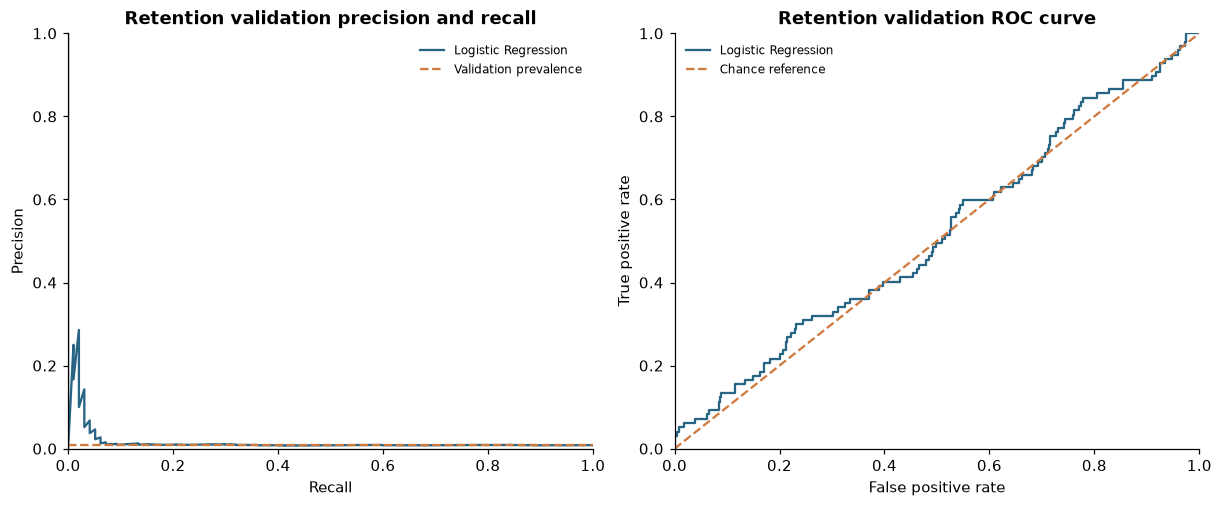

In [39]:
prior_probability = prior_baseline.predict_proba(dummy_validation_input)[:, 1]
logistic_probability = logistic_baseline.predict_proba(X_validation)[:, 1]

retention_baseline_rows = []
validation_confusion_matrices = {}
for model_name, probability in [
    ("Training prior", prior_probability),
    ("Logistic Regression", logistic_probability),
]:
    prediction = probability >= 0.5
    matrix = confusion_matrix(y_validation, prediction, labels=[0, 1])
    validation_confusion_matrices[model_name] = matrix
    retention_baseline_rows.append({
        "model": model_name,
        "average_precision": average_precision_score(y_validation, probability),
        "roc_auc": roc_auc_score(y_validation, probability),
        "brier_score": brier_score_loss(y_validation, probability),
        "precision_at_0_5": precision_score(y_validation, prediction, zero_division=0),
        "recall_at_0_5": recall_score(y_validation, prediction, zero_division=0),
        "f1_at_0_5": f1_score(y_validation, prediction, zero_division=0),
        "predicted_positives": int(prediction.sum()),
    })
retention_baseline_results = pd.DataFrame(retention_baseline_rows)
print(retention_baseline_results.round(6).to_string(index=False))
print()
for model_name, matrix in validation_confusion_matrices.items():
    print(model_name)
    print(pd.DataFrame(matrix, index=["Actual non-repeat", "Actual repeat"],
                       columns=["Predicted non-repeat", "Predicted repeat"]).to_string())

pr_precision, pr_recall, _ = precision_recall_curve(y_validation, logistic_probability)
false_positive_rate, true_positive_rate, _ = roc_curve(y_validation, logistic_probability)
validation_prevalence = float(y_validation.mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].plot(pr_recall, pr_precision, color="#286484", label="Logistic Regression")
axes[0].axhline(validation_prevalence, color="#d17a3e", linestyle="--", label="Validation prevalence")
axes[0].set(xlim=(0, 1), ylim=(0, 1), title="Retention validation precision and recall",
            xlabel="Recall", ylabel="Precision")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(false_positive_rate, true_positive_rate, color="#286484", label="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "--", color="#d17a3e", label="Chance reference")
axes[1].set(xlim=(0, 1), ylim=(0, 1), title="Retention validation ROC curve",
            xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(frameon=False, fontsize=8)
plt.show()


### 6.3 Historical popularity and top-K metrics

Rank candidate products by the number of distinct historical buyers before the recommendation validation cutoff. Break equal-count ties by product identifier for reproducibility. Exclude each customer's already purchased products.

Return readable category labels alongside IDs and historical buyer counts. For a new customer, the same historical popularity list is the fallback. A metadata-only new item has no popularity evidence and is outside this baseline's candidate catalog.

Precision at K divides hits by K. Recall divides hits by the number of relevant future discovery items. NDCG discounts lower-ranked hits and normalizes against the ideal ordering. These formulas adapt the Week 10 helper definitions to binary purchase relevance. Global-mean and user-mean rating prediction are appropriate only for a separately justified explicit-rating task.


In [40]:
ranking_validation = recommendation_partitions["validation"]
popularity_table = (
    ranking_validation["history_pairs"].groupby("item")
    .size().rename("historical_buyers").reset_index()
    .sort_values(["historical_buyers", "item"], ascending=[False, True])
    .reset_index(drop=True)
)
popularity_items = popularity_table["item"].tolist()
popularity_counts = popularity_table.set_index("item")["historical_buyers"]
seen_products_by_user = (
    ranking_validation["history_pairs"].groupby("user")["item"].agg(set).to_dict()
)
category_lookup = products_prepared.set_index("product_id")["category_label"]

def recommend_popular(user, n=5):
    if not isinstance(n, int) or isinstance(n, bool) or not 1 <= n <= 100:
        raise ValueError("n must be an integer from 1 to 100.")
    seen = seen_products_by_user.get(user, set())
    selected = []
    for item in popularity_items:
        if item not in seen:
            selected.append(item)
        if len(selected) == n:
            break
    return pd.DataFrame({
        "product_id": selected,
        "category": category_lookup.reindex(selected).to_numpy(),
        "historical_buyers": popularity_counts.reindex(selected).to_numpy(),
    })

def top_k_metrics(recommended, relevant, k):
    if not isinstance(k, int) or isinstance(k, bool) or k < 1:
        raise ValueError("k must be a positive integer.")
    if len(set(recommended[:k])) != len(recommended[:k]):
        raise ValueError("Recommendations must be unique.")
    relevance = set(relevant)
    hits = np.array([item in relevance for item in recommended[:k]], dtype=float)
    discounts = 1 / np.log2(np.arange(len(hits)) + 2)
    ideal = (1 / np.log2(np.arange(min(k, len(relevance))) + 2)).sum()
    return {
        "precision": float(hits.sum() / k),
        "recall": float(hits.sum() / len(relevance)) if relevance else 0.0,
        "ndcg": float((hits * discounts).sum() / ideal) if ideal else 0.0,
        "hit_rate": float(hits.any()),
    }

print("Popularity candidates fitted from pre-validation purchase history:", len(popularity_items))
print(popularity_table.head(5).to_string(index=False))


Popularity candidates fitted from pre-validation purchase history: 22964
                            item  historical_buyers
99a4788cb24856965c36a24e339b6058                399
aca2eb7d00ea1a7b8ebd4e68314663af                281
422879e10f46682990de24d770e7f83d                265
154e7e31ebfa092203795c972e5804a6                253
389d119b48cf3043d311335e499d9c6b                252


In [41]:
relevance_by_user = ranking_validation["relevance"].groupby("user")["item"].agg(set).to_dict()
ranking_user_rows = []

for user, relevant in sorted(relevance_by_user.items()):
    recommended = recommend_popular(user, n=10)["product_id"].tolist()
    for k in [5, 10]:
        row = {"user": user, "k": k}
        row.update(top_k_metrics(recommended, relevant, k))
        ranking_user_rows.append(row)

ranking_user_results = pd.DataFrame(ranking_user_rows)
popularity_baseline_results = ranking_user_results.groupby("k").agg(
    users=("user", "nunique"),
    precision=("precision", "mean"),
    recall=("recall", "mean"),
    ndcg=("ndcg", "mean"),
    hit_rate=("hit_rate", "mean"),
).reset_index()

recommended_catalog = set()
for user in relevance_by_user:
    recommended_catalog.update(recommend_popular(user, n=10)["product_id"])
popularity_catalog_coverage = len(recommended_catalog) / len(popularity_items)

print(popularity_baseline_results.round(6).to_string(index=False))
print(f"Catalog coverage at 10 over evaluated warm users: {100 * popularity_catalog_coverage:.4f}%")
print("New-customer fallback example:")
new_user_recommendations = recommend_popular("__new_customer__", n=5)
print(new_user_recommendations.to_string(index=False))


 k  users  precision   recall     ndcg  hit_rate
 5     90   0.002222 0.011111 0.005556  0.011111
10     90   0.002222 0.022222 0.009061  0.022222
Catalog coverage at 10 over evaluated warm users: 0.0479%
New-customer fallback example:
                      product_id        category  historical_buyers
99a4788cb24856965c36a24e339b6058  bed_bath_table                399
aca2eb7d00ea1a7b8ebd4e68314663af furniture_decor                281
422879e10f46682990de24d770e7f83d    garden_tools                265
154e7e31ebfa092203795c972e5804a6   health_beauty                253
389d119b48cf3043d311335e499d9c6b    garden_tools                252


### 6.4 Initial uncertainty and baseline checks

Bootstrap validation customers for approximate 95-percent percentile intervals. Retention intervals condition on the fitted Logistic Regression model and observed validation population. Recommendation intervals condition on the 90 eligible warm users. These intervals do not measure temporal drift, training variability, or cold-customer ranking quality.

This baseline uses one fixed configuration on one validation split. The final repeated-run and external-benchmark comparison remains part of later modeling and tuning.


In [42]:
rng = np.random.default_rng(42)
validation_labels = y_validation.to_numpy()
bootstrap_average_precision = []
for _ in range(300):
    indices = rng.integers(0, len(validation_labels), size=len(validation_labels))
    labels = validation_labels[indices]
    if np.unique(labels).size == 2:
        bootstrap_average_precision.append(
            average_precision_score(labels, logistic_probability[indices])
        )

ndcg_at_5_values = ranking_user_results.loc[ranking_user_results["k"].eq(5), "ndcg"].to_numpy()
bootstrap_ndcg = []
for _ in range(1000):
    sampled = rng.choice(ndcg_at_5_values, size=len(ndcg_at_5_values), replace=True)
    bootstrap_ndcg.append(float(sampled.mean()))

baseline_uncertainty = pd.DataFrame([
    {
        "metric": "Logistic validation average precision",
        "lower_95": float(np.quantile(bootstrap_average_precision, 0.025)),
        "upper_95": float(np.quantile(bootstrap_average_precision, 0.975)),
        "resamples": len(bootstrap_average_precision),
    },
    {
        "metric": "Popularity validation NDCG at 5",
        "lower_95": float(np.quantile(bootstrap_ndcg, 0.025)),
        "upper_95": float(np.quantile(bootstrap_ndcg, 0.975)),
        "resamples": len(bootstrap_ndcg),
    },
])
print(baseline_uncertainty.round(6).to_string(index=False))


                               metric  lower_95  upper_95  resamples
Logistic validation average precision  0.008922  0.044339        300
      Popularity validation NDCG at 5  0.000000  0.016667       1000


In [43]:
np.testing.assert_allclose(
    numeric_imputer.statistics_,
    X_train[RETENTION_NUMERIC_FEATURES].median().to_numpy(),
)
assert int(numeric_scaler.n_samples_seen_) == len(X_train)
assert set(state_encoder.categories_[0]) == set(X_train["customer_state"])
assert logistic_baseline.named_steps["classifier"].n_iter_.max() < 2000
assert not np.isnan(transformed_validation.data).any()
assert np.isfinite(transformed_validation.data).all()
assert np.isfinite(logistic_probability).all()
assert ((logistic_probability >= 0) & (logistic_probability <= 1)).all()
np.testing.assert_allclose(prior_probability, y_train.mean())
assert np.isclose(
    average_precision_score(y_validation, prior_probability), y_validation.mean()
)

toy_metrics = top_k_metrics(["A", "B", "C"], {"B", "D"}, 3)
assert np.isclose(toy_metrics["precision"], 1 / 3)
assert np.isclose(toy_metrics["recall"], 1 / 2)
assert np.isclose(toy_metrics["ndcg"], (1 / np.log2(3)) / (1 + 1 / np.log2(3)))

for user in relevance_by_user:
    recommendations = recommend_popular(user, n=10)
    assert recommendations["product_id"].is_unique
    assert set(recommendations["product_id"]).isdisjoint(seen_products_by_user[user])
    assert recommendations["product_id"].isin(ranking_validation["candidate_items"]).all()
assert len(new_user_recommendations) == 5
assert new_user_recommendations["category"].notna().all()

single_history_user = next(user for user, seen in seen_products_by_user.items() if len(seen) == 1)
assert len(recommend_popular(single_history_user, n=5)) == 5
assert set(recommend_popular(single_history_user, n=5)["product_id"]).isdisjoint(
    seen_products_by_user[single_history_user]
)
assert "__metadata_only_new_item__" not in set(popularity_items)
assert set(popularity_items) == set(ranking_validation["candidate_items"])
assert ranking_user_results["user"].nunique() == ranking_validation["relevance"]["user"].nunique()

print("Training-only preprocessing, prior probabilities, metric formulas, and recommendation checks passed.")
print("Final test performance remains reserved for the locked model comparison.")


Training-only preprocessing, prior probabilities, metric formulas, and recommendation checks passed.
Final test performance remains reserved for the locked model comparison.



### Baseline results and interpretation

| model | average_precision | roc_auc | brier_score | predicted_positives |
| --- | --- | --- | --- | --- |
| Training prior | 0.008243 | 0.5 | 0.008177 | 0 |
| Logistic Regression | 0.016882 | 0.515552 | 0.00819 | 0 |

| k | users | precision | recall | ndcg | hit_rate |
| --- | --- | --- | --- | --- | --- |
| 5 | 90 | 0.002222 | 0.011111 | 0.005556 | 0.011111 |
| 10 | 90 | 0.002222 | 0.022222 | 0.009061 | 0.022222 |

| metric | lower_95 | upper_95 | resamples |
| --- | --- | --- | --- |
| Logistic validation average precision | 0.008922 | 0.044339 | 300 |
| Popularity validation NDCG at 5 | 0.0 | 0.016667 | 1000 |Logistic Regression has weak overall validation discrimination. Its average precision exceeds the constant prior's value, while its ROC-AUC is close to chance and its Brier score is slightly worse than the prior's. Both models predict zero positives at 0.5. This threshold behavior reflects the rare outcome and should be revisited with a justified decision policy after comparing models.

Popularity produces one user hit at five recommendations and two at ten in the 90-user warm-validation cohort. Its catalog coverage is approximately 0.0479 percent at ten recommendations. The result establishes a low initial benchmark with limited evaluated coverage.

Bootstrap intervals are conditional on the observed validation customers and fitted model. They do not replace future temporal validation or repeated training comparisons. The illustrative metric sanity check is separate from the starter's required collaborative by-hand calculation.

The two reference notebooks continue to guide the workflow. The map near the notebook introduction distinguishes implemented adaptations from planned methods.

**Completed** — Training-only preprocessing, prior and logistic retention baselines, implicit popularity recommendation, validation metrics, a validation curve figure, conditional bootstrap intervals, and baseline integrity checks.

**Next topic** — Comparative models, beginning with KNN and trees for retention and content-based recommendations.

**Topic commit message** — `feat: add training-only preprocessing and validated baseline models`.

Review and commit notebook, pipeline notes, README, and requirements together.